In [35]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
import warnings

## Los datos se obtuvieron de la página web:

https://osdr.nasa.gov/bio/repo/data/studies/OSD-569


# Diccionario de columnas: LSDS-7 Complete Blood Count (CBC)

Cada indicador tiene 3 columnas: `_value_` (valor medido), `_range_min_` (límite normal inferior) y `_range_max_` (límite normal superior), según el laboratorio.

1. `Sample Name` → Identificador de la muestra: tripulante (C001–C004) y día (L-92 a R+194).
2. `absolute_basophils_value_cells_per_microliter` → Basófilos medidos (células/µL).
3. `absolute_basophils_range_min_cells_per_microliter` → Límite normal inferior de basófilos.
4. `absolute_basophils_range_max_cells_per_microliter` → Límite normal superior de basófilos.
5. `absolute_eosinophils_value_cells_per_microliter` → Eosinófilos medidos (células/µL).
6. `absolute_eosinophils_range_min_cells_per_microliter` → Límite normal inferior de eosinófilos.
7. `absolute_eosinophils_range_max_cells_per_microliter` → Límite normal superior de eosinófilos.
8. `absolute_lymphocytes_value_cells_per_microliter` → Linfocitos medidos (células/µL).
9. `absolute_lymphocytes_range_min_cells_per_microliter` → Límite normal inferior de linfocitos.
10. `absolute_lymphocytes_range_max_cells_per_microliter` → Límite normal superior de linfocitos.
11. `absolute_monocytes_value_cells_per_microliter` → Monocitos medidos (células/µL).
12. `absolute_monocytes_range_min_cells_per_microliter` → Límite normal inferior de monocitos.
13. `absolute_monocytes_range_max_cells_per_microliter` → Límite normal superior de monocitos.
14. `absolute_neutrophils_value_cells_per_microliter` → Neutrófilos medidos (células/µL).
15. `absolute_neutrophils_range_min_cells_per_microliter` → Límite normal inferior de neutrófilos.
16. `absolute_neutrophils_range_max_cells_per_microliter` → Límite normal superior de neutrófilos.
17. `basophils_value_percent` → Basófilos como porcentaje del total de glóbulos blancos.
18. `basophils_range_min_percent` → Límite normal inferior de basófilos (%).
19. `basophils_range_max_percent` → Límite normal superior de basófilos (%).
20. `eosinophils_value_percent` → Eosinófilos como porcentaje de los glóbulos blancos.
21. `eosinophils_range_min_percent` → Límite normal inferior de eosinófilos (%).
22. `eosinophils_range_max_percent` → Límite normal superior de eosinófilos (%).
23. `hematocrit_value_percent` → Hematocrito: porcentaje de la sangre compuesto por glóbulos rojos.
24. `hematocrit_range_min_percent` → Límite normal inferior del hematocrito.
25. `hematocrit_range_max_percent` → Límite normal superior del hematocrito.
26. `hemoglobin_value_percent` → Hemoglobina medida (g/dL).
27. `hemoglobin_range_min_percent` → Límite normal inferior de hemoglobina.
28. `hemoglobin_range_max_percent` → Límite normal superior de hemoglobina.
29. `lymphocytes_value_percent` → Linfocitos como porcentaje de los glóbulos blancos.
30. `lymphocytes_range_min_percent` → Límite normal inferior de linfocitos (%).
31. `lymphocytes_range_max_percent` → Límite normal superior de linfocitos (%).
32. `mch_value_picogram` → MCH: cantidad promedio de hemoglobina por glóbulo rojo (pg).
33. `mch_range_min_picogram` → Límite normal inferior de MCH.
34. `mch_range_max_picogram` → Límite normal superior de MCH.
35. `mchc_value_grams_per_deciliter` → MCHC: concentración de hemoglobina en los glóbulos rojos (g/dL).
36. `mchc_range_min_grams_per_deciliter` → Límite normal inferior de MCHC.
37. `mchc_range_max_grams_per_deciliter` → Límite normal superior de MCHC.
38. `mcv_value_femtoliter` → MCV: volumen corpuscular medio o tamaño promedio de los glóbulos rojos (fL).
39. `mcv_range_min_femtoliter` → Límite normal inferior de MCV.
40. `mcv_range_max_femtoliter` → Límite normal superior de MCV.
41. `monocytes_value_percent` → Monocitos como porcentaje de los glóbulos blancos.
42. `monocytes_range_min_percent` → Límite normal inferior de monocitos (%).
43. `monocytes_range_max_percent` → Límite normal superior de monocitos (%).
44. `mpv_value_femtoliter` → MPV: volumen plaquetario medio o tamaño promedio de las plaquetas (fL).
45. `mpv_range_min_femtoliter` → Límite normal inferior de MPV.
46. `mpv_range_max_femtoliter` → Límite normal superior de MPV.
47. `neutrophils_value_percent` → Neutrófilos como porcentaje de los glóbulos blancos.
48. `neutrophils_range_min_percent` → Límite normal inferior de neutrófilos (%).
49. `neutrophils_range_max_percent` → Límite normal superior de neutrófilos (%).
50. `platelet_count_value_thousand_per_microliter` → Cantidad de plaquetas medidas (miles/µL).
51. `platelet_count_range_min_thousand_per_microliter` → Límite normal inferior de plaquetas.
52. `platelet_count_range_max_thousand_per_microliter` → Límite normal superior de plaquetas.
53. `rdw_value_percent` → RDW: variación del tamaño de los glóbulos rojos (%).
54. `rdw_range_min_percent` → Límite normal inferior de RDW.
55. `rdw_range_max_percent` → Límite normal superior de RDW.
56. `red_blood_cell_count_value_million_per_microliter` → Cantidad de glóbulos rojos medidos (millones/µL).
57. `red_blood_cell_count_range_min_million_per_microliter` → Límite normal inferior de glóbulos rojos.
58. `red_blood_cell_count_range_max_million_per_microliter` → Límite normal superior de glóbulos rojos.
59. `white_blood_cell_count_value_thousand_per_microliter` → Cantidad total de glóbulos blancos medidos (miles/µL).
60. `white_blood_cell_count_range_min_thousand_per_microliter` → Límite normal inferior de glóbulos blancos.
61. `white_blood_cell_count_range_max_thousand_per_microliter` → Límite normal superior de glóbulos blancos.

## Importación de datos

In [36]:
import pandas as pd

# Cargar el archivo CSV desde la carpeta específica en Google Drive
file_path = '/content/drive/MyDrive/Nasa space app 2026/LSDS-7_Complete_Blood_Count_CBC_TRANSFORMED.csv'
try:
    df = pd.read_csv(file_path)
    display(df)
except FileNotFoundError:
    print(f"No se encontró el archivo en la ruta: {file_path}. Por favor, verifica el nombre de la carpeta y del archivo.")

,Sample Name,absolute_basophils_value_cells_per_microliter,absolute_basophils_range_min_cells_per_microliter,absolute_basophils_range_max_cells_per_microliter,absolute_eosinophils_value_cells_per_microliter,absolute_eosinophils_range_min_cells_per_microliter,absolute_eosinophils_range_max_cells_per_microliter,absolute_lymphocytes_value_cells_per_microliter,absolute_lymphocytes_range_min_cells_per_microliter,absolute_lymphocytes_range_max_cells_per_microliter,absolute_monocytes_value_cells_per_microliter,absolute_monocytes_range_min_cells_per_microliter,absolute_monocytes_range_max_cells_per_microliter,absolute_neutrophils_value_cells_per_microliter,absolute_neutrophils_range_min_cells_per_microliter,absolute_neutrophils_range_max_cells_per_microliter,basophils_value_percent,basophils_range_min_percent,basophils_range_max_percent,eosinophils_value_percent,eosinophils_range_min_percent,eosinophils_range_max_percent,hematocrit_value_percent,hematocrit_range_min_percent,hematocrit_range_max_percent,hemoglobin_value_percent,hemoglobin_range_min_percent,hemoglobin_range_max_percent,lymphocytes_value_percent,lymphocytes_range_min_percent,lymphocytes_range_max_percent,mch_value_picogram,mch_range_min_picogram,mch_range_max_picogram,mchc_value_grams_per_deciliter,mchc_range_min_grams_per_deciliter,mchc_range_max_grams_per_deciliter,mcv_value_femtoliter,mcv_range_min_femtoliter,mcv_range_max_femtoliter,monocytes_value_percent,monocytes_range_min_percent,monocytes_range_max_percent,mpv_value_femtoliter,mpv_range_min_femtoliter,mpv_range_max_femtoliter,neutrophils_value_percent,neutrophils_range_min_percent,neutrophils_range_max_percent,platelet_count_value_thousand_per_microliter,platelet_count_range_min_thousand_per_microliter,platelet_count_range_max_thousand_per_microliter,rdw_value_percent,rdw_range_min_percent,rdw_range_max_percent,red_blood_cell_count_value_million_per_microliter,red_blood_cell_count_range_min_million_per_microliter,red_blood_cell_count_range_max_million_per_microliter,white_blood_cell_count_value_thousand_per_microliter,white_blood_cell_count_range_min_thousand_per_microliter,white_blood_cell_count_range_max_thousand_per_microliter
0,C001_whole-blood_L-3_cbc,49,0,200,161,15,500,2667,850,3900,553,200,950,3570.0,1500,7800,0.7,0,2,2.3,0,8,44.5,38.5,50,14.7,13.2,17.1,38.1,15,49,31.3,27.0,33.0,33.0,32.0,36.0,94.9,80.0,100.0,7.9,0,13,10.9,7.5,12.5,51.0,38,80,258.0,140,400,12.6,11,15,4.69,4.2,5.8,7.0,3.8,10.8
1,C001_whole-blood_L-44_cbc,50,0,200,204,15,500,1859,850,3900,391,200,950,2998.0,1500,7800,0.9,0,2,3.7,0,8,45.1,38.5,50,14.9,13.2,17.1,33.8,15,49,30.7,27.0,33.0,33.0,32.0,36.0,93.0,80.0,100.0,7.1,0,13,10.6,7.5,12.5,54.5,38,80,237.0,140,400,12.6,11,15,4.85,4.2,5.8,5.5,3.8,10.8
2,C001_whole-blood_L-92_cbc,70,0,200,259,15,500,2241,850,3900,481,200,950,2349.0,1500,7800,1.3,0,2,4.8,0,8,42.5,38.5,50,14.1,13.2,17.1,41.5,15,49,30.8,27.0,33.0,33.2,32.0,36.0,92.8,80.0,100.0,8.9,0,13,10.3,7.5,12.5,43.5,38,80,241.0,140,400,13.0,11,15,4.58,4.2,5.8,5.4,3.8,10.8
3,C001_whole-blood_R+1_cbc,50,0,200,170,15,500,1640,850,3900,455,200,950,2685.0,1500,7800,1.0,0,2,3.4,0,8,43.6,38.5,50,14.7,13.2,17.1,32.8,15,49,30.4,27.0,33.0,33.7,32.0,36.0,90.1,80.0,100.0,9.1,0,13,10.8,7.5,12.5,53.7,38,80,227.0,140,400,12.5,11,15,4.84,4.2,5.8,5.0,3.8,10.8
4,C001_whole-blood_R+194_cbc,49,0,200,221,15,500,1847,850,3900,392,200,950,2391.0,1500,7800,1.0,0,2,4.5,0,8,41.8,38.5,50,14.1,13.2,17.1,37.7,15,49,30.3,27.0,33.0,33.7,32.0,36.0,89.7,80.0,100.0,8.0,0,13,10.5,7.5,12.5,48.8,38,80,214.0,140,400,12.8,11,15,4.66,4.2,5.8,4.9,3.8,10.8
5,C001_whole-blood_R+45_cbc,59,0,200,127,15,500,2146,850,3900,368,200,950,2200.0,1500,7800,1.2,0,2,2.6,0,8,43.3,38.5,50,14.3,13.2,17.1,43.8,15,49,30.9,27.0,33.0,33.0,32.0,36.0,93.5,80.0,100.0,7.5,0,13,10.5,7.5,12.5,44.9,38,80,228.0,140,400,12.8,11,15,4.63,4.2,5.8,4.9,3.8,10.8
6,C001_whole-blood_R+82_cbc,69,0,200,181,15,500,2171,850,3900,485,200,950,1994.0,1500,7800,1.4,0,2,3.7,0,8,46.1,38.5,50,15.7,13.2,17.1,44.3,15,49,31.3,27.0,

## Limpieza de datos

In [37]:
# Columnas a eliminar según la solicitud
columns_to_drop = [
    'absolute_basophils_value_cells_per_microliter',
    'absolute_basophils_range_min_cells_per_microliter',
    'absolute_basophils_range_max_cells_per_microliter',
    'absolute_eosinophils_value_cells_per_microliter',
    'absolute_eosinophils_range_min_cells_per_microliter',
    'absolute_eosinophils_range_max_cells_per_microliter',
    'absolute_monocytes_value_cells_per_microliter',
    'absolute_monocytes_range_min_cells_per_microliter',
    'absolute_monocytes_range_max_cells_per_microliter',
    'basophils_value_percent',
    'basophils_range_min_percent',
    'basophils_range_max_percent',
    'eosinophils_value_percent',
    'eosinophils_range_min_percent',
    'eosinophils_range_max_percent',
    'lymphocytes_value_percent',
    'lymphocytes_range_min_percent',
    'lymphocytes_range_max_percent',
    'monocytes_value_percent',
    'monocytes_range_min_percent',
    'monocytes_range_max_percent',
    'neutrophils_value_percent',
    'neutrophils_range_min_percent',
    'neutrophils_range_max_percent',
    'mch_value_picogram',
    'mch_range_min_picogram',
    'mch_range_max_picogram',
    'mchc_value_grams_per_deciliter',
    'mchc_range_min_grams_per_deciliter',
    'mchc_range_max_grams_per_deciliter',
    'mcv_value_femtoliter',
    'mcv_range_min_femtoliter',
    'mcv_range_max_femtoliter',
    'mpv_value_femtoliter',
    'mpv_range_min_femtoliter',
    'mpv_range_max_femtoliter',
    'rdw_value_percent',
    'rdw_range_min_percent',
    'rdw_range_max_percent'
]

# Eliminar las columnas que existan en el DataFrame
df = df.drop(columns=[col for col in columns_to_drop if col in df.columns])
display(df)

,Sample Name,absolute_lymphocytes_value_cells_per_microliter,absolute_lymphocytes_range_min_cells_per_microliter,absolute_lymphocytes_range_max_cells_per_microliter,absolute_neutrophils_value_cells_per_microliter,absolute_neutrophils_range_min_cells_per_microliter,absolute_neutrophils_range_max_cells_per_microliter,hematocrit_value_percent,hematocrit_range_min_percent,hematocrit_range_max_percent,hemoglobin_value_percent,hemoglobin_range_min_percent,hemoglobin_range_max_percent,platelet_count_value_thousand_per_microliter,platelet_count_range_min_thousand_per_microliter,platelet_count_range_max_thousand_per_microliter,red_blood_cell_count_value_million_per_microliter,red_blood_cell_count_range_min_million_per_microliter,red_blood_cell_count_range_max_million_per_microliter,white_blood_cell_count_value_thousand_per_microliter,white_blood_cell_count_range_min_thousand_per_microliter,white_blood_cell_count_range_max_thousand_per_microliter
0,C001_whole-blood_L-3_cbc,2667,850,3900,3570.0,1500,7800,44.5,38.5,50,14.7,13.2,17.1,258.0,140,400,4.69,4.2,5.8,7.0,3.8,10.8
1,C001_whole-blood_L-44_cbc,1859,850,3900,2998.0,1500,7800,45.1,38.5,50,14.9,13.2,17.1,237.0,140,400,4.85,4.2,5.8,5.5,3.8,10.8
2,C001_whole-blood_L-92_cbc,2241,850,3900,2349.0,1500,7800,42.5,38.5,50,14.1,13.2,17.1,241.0,140,400,4.58,4.2,5.8,5.4,3.8,10.8
3,C001_whole-blood_R+1_cbc,1640,850,3900,2685.0,1500,7800,43.6,38.5,50,14.7,13.2,17.1,227.0,140,400,4.84,4.2,5.8,5.0,3.8,10.8
4,C001_whole-blood_R+194_cbc,1847,850,3900,2391.0,1500,7800,41.8,38.5,50,14.1,13.2,17.1,214.0,140,400,4.66,4.2,5.8,4.9,3.8,10.8
5,C001_whole-blood_R+45_cbc,2146,850,3900,2200.0,1500,7800,43.3,38.5,50,14.3,13.2,17.1,228.0,140,400,4.63,4.2,5.8,4.9,3.8,10.8
6,C001_whole-blood_R+82_cbc,2171,850,3900,1994.0,1500,7800,46.1,38.5,50,15.7,13.2,17.1,257.0,140,400,5.02,4.2,5.8,4.9,3.8,10.8
7,C002_whole-blood_L-3_cbc,2873,850,3900,3701.0,1500,7800,35.9,35.0,45,11.5,11.7,15.5,241.0,140,400,3.72,3.8,5.1,7.2,3.8,10.8
8,C002_whole-blood_L-44_cbc,1982,850,3900,2873.0,1500,7800,37.8,35.0,45,12.8,11.7,15.5,229.0,140,400,3.93,3.8,5.1,5.4,3.8,10.8
9,C002_whole-blood_L-92_cbc,2119,850,3900,3705.0,1500,7800,40.8,35.0,45,13.2,11.7,15.5,241.0,140,400,4.36,3.8,5.1,6.5,3.8,10.8


### Procesamiento y Estructuración de la Muestra en Español

En este paso realizamos la descomposición de la columna `Sample Name` para estructurar la información clave en columnas individuales escritas en español:

1. **Tripulante**: Extrae el código identificador del miembro de la tripulación (aquellos que comienzan con **C**, como `C001`, `C002`, etc.).
2. **Fase de Vuelo**: Determina el momento temporal de la muestra:
   * **Antes del Vuelo** (si contiene la letra **L** de *Launch*).
   * **Después del Vuelo** (si contiene la letra **R** de *Return*).
3. **Días**: Extrae el número de días transcurridos respecto al lanzamiento, aplicando el signo adecuado:
   * Valores **negativos** para el periodo previo al vuelo (ej. `-92` días).
   * Valores **positivos** para el periodo posterior al vuelo (ej. `194` días).

Finalmente, colocamos estas nuevas columnas al inicio del DataFrame y ordenamos cronológicamente los registros por **Tripulante** y **Días** para facilitar el análisis secuencial.

In [38]:
import re

# Extrae del Sample Name: tripulante, fase y días con signo
# Formato esperado: C001_whole-blood_L-92_cbc  /  C001_whole-blood_R+1_cbc
PATRON = re.compile(r'^(C\d+)_.*?_([LR])([-+])(\d+)_')

def parsear_muestra(sample_name):
    m = PATRON.match(sample_name)
    if not m:
        return pd.Series([None, 'Desconocido', None])
    tripulante, letra, signo, dias = m.groups()
    fase = 'Antes del Vuelo' if letra == 'L' else 'Después del Vuelo'
    dias = -int(dias) if letra == 'L' else int(dias)   # L = negativo, R = positivo
    return pd.Series([tripulante, fase, dias])

df[['Tripulante', 'Fase de Vuelo', 'Días']] = df['Sample Name'].apply(parsear_muestra)

# Colocar las columnas nuevas al principio
nuevas = ['Tripulante', 'Fase de Vuelo', 'Días']
df = df[nuevas + [c for c in df.columns if c not in nuevas]]

# Ordenar cronológicamente y reiniciar el índice
df = df.sort_values(['Tripulante', 'Días']).reset_index(drop=True)

df

,Tripulante,Fase de Vuelo,Días,Sample Name,absolute_lymphocytes_value_cells_per_microliter,absolute_lymphocytes_range_min_cells_per_microliter,absolute_lymphocytes_range_max_cells_per_microliter,absolute_neutrophils_value_cells_per_microliter,absolute_neutrophils_range_min_cells_per_microliter,absolute_neutrophils_range_max_cells_per_microliter,hematocrit_value_percent,hematocrit_range_min_percent,hematocrit_range_max_percent,hemoglobin_value_percent,hemoglobin_range_min_percent,hemoglobin_range_max_percent,platelet_count_value_thousand_per_microliter,platelet_count_range_min_thousand_per_microliter,platelet_count_range_max_thousand_per_microliter,red_blood_cell_count_value_million_per_microliter,red_blood_cell_count_range_min_million_per_microliter,red_blood_cell_count_range_max_million_per_microliter,white_blood_cell_count_value_thousand_per_microliter,white_blood_cell_count_range_min_thousand_per_microliter,white_blood_cell_count_range_max_thousand_per_microliter
0,C001,Antes del Vuelo,-92,C001_whole-blood_L-92_cbc,2241,850,3900,2349.0,1500,7800,42.5,38.5,50,14.1,13.2,17.1,241.0,140,400,4.58,4.2,5.8,5.4,3.8,10.8
1,C001,Antes del Vuelo,-44,C001_whole-blood_L-44_cbc,1859,850,3900,2998.0,1500,7800,45.1,38.5,50,14.9,13.2,17.1,237.0,140,400,4.85,4.2,5.8,5.5,3.8,10.8
2,C001,Antes del Vuelo,-3,C001_whole-blood_L-3_cbc,2667,850,3900,3570.0,1500,7800,44.5,38.5,50,14.7,13.2,17.1,258.0,140,400,4.69,4.2,5.8,7.0,3.8,10.8
3,C001,Después del Vuelo,1,C001_whole-blood_R+1_cbc,1640,850,3900,2685.0,1500,7800,43.6,38.5,50,14.7,13.2,17.1,227.0,140,400,4.84,4.2,5.8,5.0,3.8,10.8
4,C001,Después del Vuelo,45,C001_whole-blood_R+45_cbc,2146,850,3900,2200.0,1500,7800,43.3,38.5,50,14.3,13.2,17.1,228.0,140,400,4.63,4.2,5.8,4.9,3.8,10.8
5,C001,Después del Vuelo,82,C001_whole-blood_R+82_cbc,2171,850,3900,1994.0,1500,7800,46.1,38.5,50,15.7,13.2,17.1,257.0,140,400,5.02,4.2,5.8,4.9,3.8,10.8
6,C001,Después del Vuelo,194,C001_whole-blood_R+194_cbc,1847,850,3900,2391.0,1500,7800,41.8,38.5,50,14.1,13.2,17.1,214.0,140,400,4.66,4.2,5.8,4.9,3.8,10.8
7,C002,Antes del Vuelo,-92,C002_whole-blood_L-92_cbc,2119,850,3900,3705.0,1500,7800,40.8,35.0,45,13.2,11.7,15.5,241.0,140,400,4.36,3.8,5.1,6.5,3.8,10.8
8,C002,Antes del Vuelo,-44,C002_whole-blood_L-44_cbc,1982,850,3900,2873.0,1500,7800,37.8,35.0,45,12.8,11.7,15.5,229.0,140,400,3.93,3.8,5.1,5.4,3.8,10.8
9,C002,Antes del Vuelo,-3,C002_whole-blood_L-3_cbc,2873,850,3900,3701.0,1500,7800,35.9,35.0,45,11.5,11.7,15.5,241.0,140,400,3.72,3.8,5.1,7.2,3.8,10.8


In [39]:
# Quitar Sample Name
df = df.drop(columns=['Sample Name'])

# Renombrar columnas de hemoglobina: percent -> g_per_deciliter
df = df.rename(columns=lambda c: re.sub(r'^(hemoglobin_.*)_percent$',
                                        r'\1_g_per_deciliter', c))

df

,Tripulante,Fase de Vuelo,Días,absolute_lymphocytes_value_cells_per_microliter,absolute_lymphocytes_range_min_cells_per_microliter,absolute_lymphocytes_range_max_cells_per_microliter,absolute_neutrophils_value_cells_per_microliter,absolute_neutrophils_range_min_cells_per_microliter,absolute_neutrophils_range_max_cells_per_microliter,hematocrit_value_percent,hematocrit_range_min_percent,hematocrit_range_max_percent,hemoglobin_value_g_per_deciliter,hemoglobin_range_min_g_per_deciliter,hemoglobin_range_max_g_per_deciliter,platelet_count_value_thousand_per_microliter,platelet_count_range_min_thousand_per_microliter,platelet_count_range_max_thousand_per_microliter,red_blood_cell_count_value_million_per_microliter,red_blood_cell_count_range_min_million_per_microliter,red_blood_cell_count_range_max_million_per_microliter,white_blood_cell_count_value_thousand_per_microliter,white_blood_cell_count_range_min_thousand_per_microliter,white_blood_cell_count_range_max_thousand_per_microliter
0,C001,Antes del Vuelo,-92,2241,850,3900,2349.0,1500,7800,42.5,38.5,50,14.1,13.2,17.1,241.0,140,400,4.58,4.2,5.8,5.4,3.8,10.8
1,C001,Antes del Vuelo,-44,1859,850,3900,2998.0,1500,7800,45.1,38.5,50,14.9,13.2,17.1,237.0,140,400,4.85,4.2,5.8,5.5,3.8,10.8
2,C001,Antes del Vuelo,-3,2667,850,3900,3570.0,1500,7800,44.5,38.5,50,14.7,13.2,17.1,258.0,140,400,4.69,4.2,5.8,7.0,3.8,10.8
3,C001,Después del Vuelo,1,1640,850,3900,2685.0,1500,7800,43.6,38.5,50,14.7,13.2,17.1,227.0,140,400,4.84,4.2,5.8,5.0,3.8,10.8
4,C001,Después del Vuelo,45,2146,850,3900,2200.0,1500,7800,43.3,38.5,50,14.3,13.2,17.1,228.0,140,400,4.63,4.2,5.8,4.9,3.8,10.8
5,C001,Después del Vuelo,82,2171,850,3900,1994.0,1500,7800,46.1,38.5,50,15.7,13.2,17.1,257.0,140,400,5.02,4.2,5.8,4.9,3.8,10.8
6,C001,Después del Vuelo,194,1847,850,3900,2391.0,1500,7800,41.8,38.5,50,14.1,13.2,17.1,214.0,140,400,4.66,4.2,5.8,4.9,3.8,10.8
7,C002,Antes del Vuelo,-92,2119,850,3900,3705.0,1500,7800,40.8,35.0,45,13.2,11.7,15.5,241.0,140,400,4.36,3.8,5.1,6.5,3.8,10.8
8,C002,Antes del Vuelo,-44,1982,850,3900,2873.0,1500,7800,37.8,35.0,45,12.8,11.7,15.5,229.0,140,400,3.93,3.8,5.1,5.4,3.8,10.8
9,C002,Antes del Vuelo,-3,2873,850,3900,3701.0,1500,7800,35.9,35.0,45,11.5,11.7,15.5,241.0,140,400,3.72,3.8,5.1,7.2,3.8,10.8


In [40]:
pd.set_option('display.max_rows', None)       # Mostrar todas las filas
pd.set_option('display.max_columns', None)    # Mostrar todas las columnas
pd.set_option('display.max_colwidth', None)   # Mostrar el contenido completo de las celdas
pd.set_option('display.width', None)          # Sin límite de ancho

display(df)

,Tripulante,Fase de Vuelo,Días,absolute_lymphocytes_value_cells_per_microliter,absolute_lymphocytes_range_min_cells_per_microliter,absolute_lymphocytes_range_max_cells_per_microliter,absolute_neutrophils_value_cells_per_microliter,absolute_neutrophils_range_min_cells_per_microliter,absolute_neutrophils_range_max_cells_per_microliter,hematocrit_value_percent,hematocrit_range_min_percent,hematocrit_range_max_percent,hemoglobin_value_g_per_deciliter,hemoglobin_range_min_g_per_deciliter,hemoglobin_range_max_g_per_deciliter,platelet_count_value_thousand_per_microliter,platelet_count_range_min_thousand_per_microliter,platelet_count_range_max_thousand_per_microliter,red_blood_cell_count_value_million_per_microliter,red_blood_cell_count_range_min_million_per_microliter,red_blood_cell_count_range_max_million_per_microliter,white_blood_cell_count_value_thousand_per_microliter,white_blood_cell_count_range_min_thousand_per_microliter,white_blood_cell_count_range_max_thousand_per_microliter
0,C001,Antes del Vuelo,-92,2241,850,3900,2349.0,1500,7800,42.5,38.5,50,14.1,13.2,17.1,241.0,140,400,4.58,4.2,5.8,5.4,3.8,10.8
1,C001,Antes del Vuelo,-44,1859,850,3900,2998.0,1500,7800,45.1,38.5,50,14.9,13.2,17.1,237.0,140,400,4.85,4.2,5.8,5.5,3.8,10.8
2,C001,Antes del Vuelo,-3,2667,850,3900,3570.0,1500,7800,44.5,38.5,50,14.7,13.2,17.1,258.0,140,400,4.69,4.2,5.8,7.0,3.8,10.8
3,C001,Después del Vuelo,1,1640,850,3900,2685.0,1500,7800,43.6,38.5,50,14.7,13.2,17.1,227.0,140,400,4.84,4.2,5.8,5.0,3.8,10.8
4,C001,Después del Vuelo,45,2146,850,3900,2200.0,1500,7800,43.3,38.5,50,14.3,13.2,17.1,228.0,140,400,4.63,4.2,5.8,4.9,3.8,10.8
5,C001,Después del Vuelo,82,2171,850,3900,1994.0,1500,7800,46.1,38.5,50,15.7,13.2,17.1,257.0,140,400,5.02,4.2,5.8,4.9,3.8,10.8
6,C001,Después del Vuelo,194,1847,850,3900,2391.0,1500,7800,41.8,38.5,50,14.1,13.2,17.1,214.0,140,400,4.66,4.2,5.8,4.9,3.8,10.8
7,C002,Antes del Vuelo,-92,2119,850,3900,3705.0,1500,7800,40.8,35.0,45,13.2,11.7,15.5,241.0,140,400,4.36,3.8,5.1,6.5,3.8,10.8
8,C002,Antes del Vuelo,-44,1982,850,3900,2873.0,1500,7800,37.8,35.0,45,12.8,11.7,15.5,229.0,140,400,3.93,3.8,5.1,5.4,3.8,10.8
9,C002,Antes del Vuelo,-3,2873,850,3900,3701.0,1500,7800,35.9,35.0,45,11.5,11.7,15.5,241.0,140,400,3.72,3.8,5.1,7.2,3.8,10.8


In [41]:
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)
plt.rcParams['figure.max_open_warning'] = 0

assert 'df' in globals(), 'Primero carga tu DataFrame limpio en la variable df'

USAR_RANGO_FIJO = True   # True = rango pre-vuelo de cada tripulante; False = rango original de cada muestra

IND = {  # abreviatura: (nombre, prefijo de columna en df)
    'WBC':  ('Glóbulos blancos', 'white_blood_cell_count'),
    'Neut': ('Neutrófilos',      'absolute_neutrophils'),
    'Linf': ('Linfocitos',       'absolute_lymphocytes'),
    'Hb':   ('Hemoglobina',      'hemoglobin'),
    'Hct':  ('Hematocrito',      'hematocrit'),
    'RBC':  ('Glóbulos rojos',   'red_blood_cell_count'),
    'Plaq': ('Plaquetas',        'platelet_count'),
}
UNIDADES = {'WBC': '10³/µL', 'Neut': 'células/µL', 'Linf': 'células/µL', 'Hb': 'g/dL',
            'Hct': '%', 'RBC': '10⁶/µL', 'Plaq': '10³/µL'}

def col(prefijo, tipo):
    m = [c for c in df.columns if c.startswith(f'{prefijo}_{tipo}_')]
    assert len(m) == 1, f'{prefijo}_{tipo}: {len(m)} coincidencias'
    return m[0]

assert pd.api.types.is_numeric_dtype(df['Días']), 'Días debe ser numérica'

# DataFrame maestro: una fila por muestra
metricas = df[['Tripulante', 'Fase de Vuelo', 'Días']].copy()
metricas['Muestra'] = np.where(metricas['Días'] < 0, 'L' + metricas['Días'].astype(str),
                               'R+' + metricas['Días'].astype(str))
pre_vuelo  = metricas['Fase de Vuelo'] == 'Antes del Vuelo'
post_vuelo = metricas['Fase de Vuelo'] == 'Después del Vuelo'

# Valores medidos y rangos de referencia (sin modificar df)
metricas['Rango_cambio'] = False
for ab, (nombre, pre) in IND.items():
    metricas[ab] = df[col(pre, 'value')]
    mn, mx = df[col(pre, 'range_min')], df[col(pre, 'range_max')]
    if USAR_RANGO_FIJO:
        mn_f = mn.where(pre_vuelo).groupby(df['Tripulante']).transform('first')
        mx_f = mx.where(pre_vuelo).groupby(df['Tripulante']).transform('first')
        metricas['Rango_cambio'] |= (mn != mn_f) | (mx != mx_f)
        mn, mx = mn_f, mx_f
    metricas[f'{ab}_min'], metricas[f'{ab}_max'] = mn, mx

# Muestra sospechosa (solo etiqueta, no se borra nada): C003 en L-92
es_sosp = (metricas['Tripulante'] == 'C003') & (metricas['Días'] == -92)
SOSP_IND = ['Neut', 'Linf', 'Plaq']
metricas['Muestra_sospechosa'] = es_sosp

def valido(ab):
    """True donde el valor del indicador es confiable."""
    return ~es_sosp if ab in SOSP_IND else pd.Series(True, index=metricas.index)

def base_pre(serie, ok=None):
    """Media y SD pre-vuelo (L-92, L-44, L-3) por tripulante, excluyendo sospechosos."""
    m = pre_vuelo & serie.notna()
    if ok is not None:
        m = m & ok
    g = serie.where(m).groupby(metricas['Tripulante'])
    return g.transform('mean'), g.transform('std')

print(metricas.shape, '| filas sospechosas:', int(es_sosp.sum()),
      '| filas con rango distinto al de referencia:', int(metricas['Rango_cambio'].sum()))

(28, 27) | filas sospechosas: 1 | filas con rango distinto al de referencia: 4


In [42]:
# Función para realizar graficos:

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})
TRIPS = sorted(metricas['Tripulante'].unique())
C_PRE, C_POST = '#4C78A8', '#F58518'
SEM_TXT = {0: 'Verde', 1: 'Amarillo', 2: 'Rojo'}
SEM_COL = ['#8fd18f', '#f2c14e', '#e4572e']
CMAP_SEM = ListedColormap(SEM_COL)

def _sub(t):
    return metricas[metricas['Tripulante'] == t].sort_values('Días').reset_index(drop=True)

def linea(col, titulo, unidad='', lo=None, hi=None, base=None, banda=None, sosp=False, show=True):
    """Evolución de una métrica: un panel por tripulante, eje X = muestra (L-92 ... R+194)."""
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
    for ax, t in zip(axes.ravel(), TRIPS):
        d = _sub(t); x = np.arange(len(d))
        pre = (d['Fase de Vuelo'] == 'Antes del Vuelo').values
        malo = d['Muestra_sospechosa'].values if sosp else np.zeros(len(d), bool)
        y = d[col].astype(float).where(~malo)
        if lo:    ax.fill_between(x, d[lo], d[hi], color='green', alpha=.12, label='Rango normal')
        if banda: ax.axhspan(*banda, color='green', alpha=.12, label='Referencia')
        if base:  ax.axhline(d[base].iloc[0], color='gray', ls=':', label='Línea base')
        ax.plot(x, y, '-', color='gray', lw=1, zorder=1)
        ax.scatter(x[pre], y[pre], color=C_PRE, s=45, zorder=3, label='Antes del vuelo')
        ax.scatter(x[~pre], y[~pre], color=C_POST, s=45, zorder=3, label='Después del vuelo')
        ax.axvline(2.5, color='k', ls='--', lw=1)
        ax.text(2.5, 1, ' Misión', transform=ax.get_xaxis_transform(), va='top', fontsize=8)
        for i in np.where(malo)[0]:
            ax.text(i, .5, 'dato\nsospechoso', transform=ax.get_xaxis_transform(),
                    color='red', ha='center', fontsize=8)
        ax.set_xticks(x); ax.set_xticklabels(d['Muestra']); ax.set_title(t); ax.set_ylabel(unidad)
    axes.ravel()[0].legend(fontsize=7, loc='best')
    fig.suptitle(titulo, fontweight='bold'); fig.tight_layout()
    if show: plt.show()
    return fig, axes

def mapa(sufijo, titulo, cmap='RdBu_r', vmin=None, vmax=None, fmt='{:.0f}', etiquetas=None):
    """Mapa de calor: filas = indicadores, columnas = muestras, un panel por tripulante."""
    inds = list(IND)
    fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
    for ax, t in zip(axes.ravel(), TRIPS):
        d = _sub(t)
        M = np.array([d[f'{ab}_{sufijo}'].astype(float).values for ab in inds])
        im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                v = M[i, j]
                txt = '·' if np.isnan(v) else (etiquetas[int(v)] if etiquetas else fmt.format(v))
                ax.text(j, i, txt, ha='center', va='center', fontsize=7)
        ax.set_xticks(range(len(d))); ax.set_xticklabels(d['Muestra'])
        ax.set_yticks(range(len(inds))); ax.set_yticklabels(inds)
        ax.axvline(2.5, color='k', lw=2); ax.set_title(t); ax.grid(False)
    if not etiquetas:
        fig.colorbar(im, ax=axes, shrink=.7)
    fig.suptitle(titulo, fontweight='bold'); plt.show()

def mapa_sem(cols, nombres, titulo):
    """Mapa de semáforo: filas = indicadores/sistemas, columnas = muestras, un panel por tripulante."""
    fig, axes = plt.subplots(2, 2, figsize=(12, 2 * (0.45 * len(cols) + 1.4)))
    for ax, t in zip(axes.ravel(), TRIPS):
        d = _sub(t)
        M = np.array([d[c].astype(float).values for c in cols])
        ax.imshow(M, cmap=CMAP_SEM, vmin=-.5, vmax=2.5, aspect='auto')
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                if np.isnan(M[i, j]):
                    ax.text(j, i, '·', ha='center', va='center', color='gray')
        ax.set_xticks(range(len(d))); ax.set_xticklabels(d['Muestra'])
        ax.set_yticks(range(len(cols))); ax.set_yticklabels(nombres)
        ax.axvline(2.5, color='k', lw=2); ax.grid(False); ax.set_title(t)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in SEM_COL]
    fig.legend(handles, list(SEM_TXT.values()), loc='lower center', ncol=3)
    fig.suptitle(titulo, fontweight='bold'); fig.tight_layout(rect=(0, .05, 1, 1)); plt.show()

## Análisis exploratorio de datos

### 2.1 Línea base personal
Media ± SD de L-92, L-44 y L-3 de cada tripulante, sin los datos sospechosos.

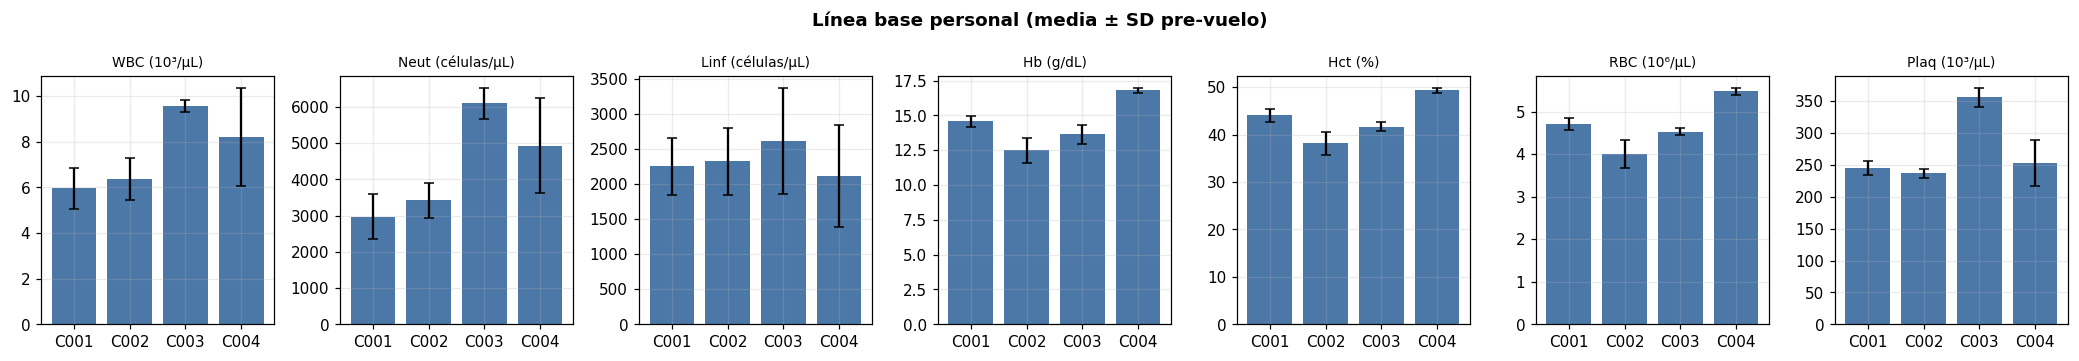

,Tripulante,WBC_base,Neut_base,Linf_base,Hb_base,Hct_base,RBC_base,Plaq_base
2,C001,5.97,2972.33,2255.67,14.57,44.03,4.71,245.33
9,C002,6.37,3426.33,2324.67,12.50,38.17,4.00,237.00
16,C003,9.57,6100.00,2619.50,13.63,41.63,4.53,356.00
23,C004,8.23,4927.67,2115.33,16.80,49.37,5.48,253.67


In [43]:
for ab in IND:
    metricas[f'{ab}_base'], metricas[f'{ab}_sd'] = base_pre(metricas[ab], valido(ab))

fig, axes = plt.subplots(1, 7, figsize=(19, 3.3))
for ax, ab in zip(axes, IND):
    b = metricas[pre_vuelo].groupby('Tripulante')[[f'{ab}_base', f'{ab}_sd']].first()
    ax.bar(b.index, b[f'{ab}_base'], yerr=b[f'{ab}_sd'], capsize=3, color=C_PRE)
    ax.set_title(f'{ab} ({UNIDADES[ab]})', fontsize=9)
fig.suptitle('Línea base personal (media ± SD pre-vuelo)', fontweight='bold'); fig.tight_layout(); plt.show()

metricas.loc[metricas['Días'] == -3, ['Tripulante'] + [f'{ab}_base' for ab in IND]].round(2)

### 2.2 Valores medidos vs. rango normal y línea base
- Banda verde = rango normal.
- Línea punteada = línea base.
- Línea discontinua vertical = misión.

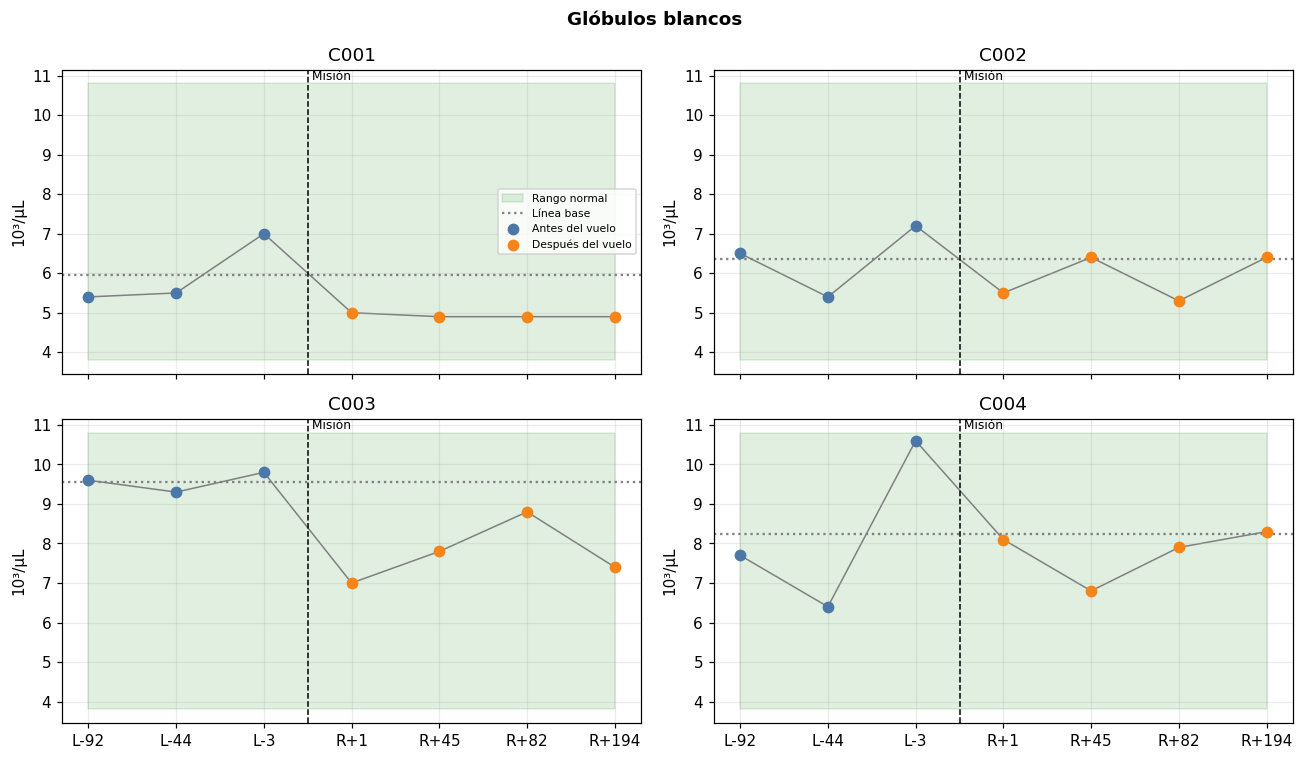

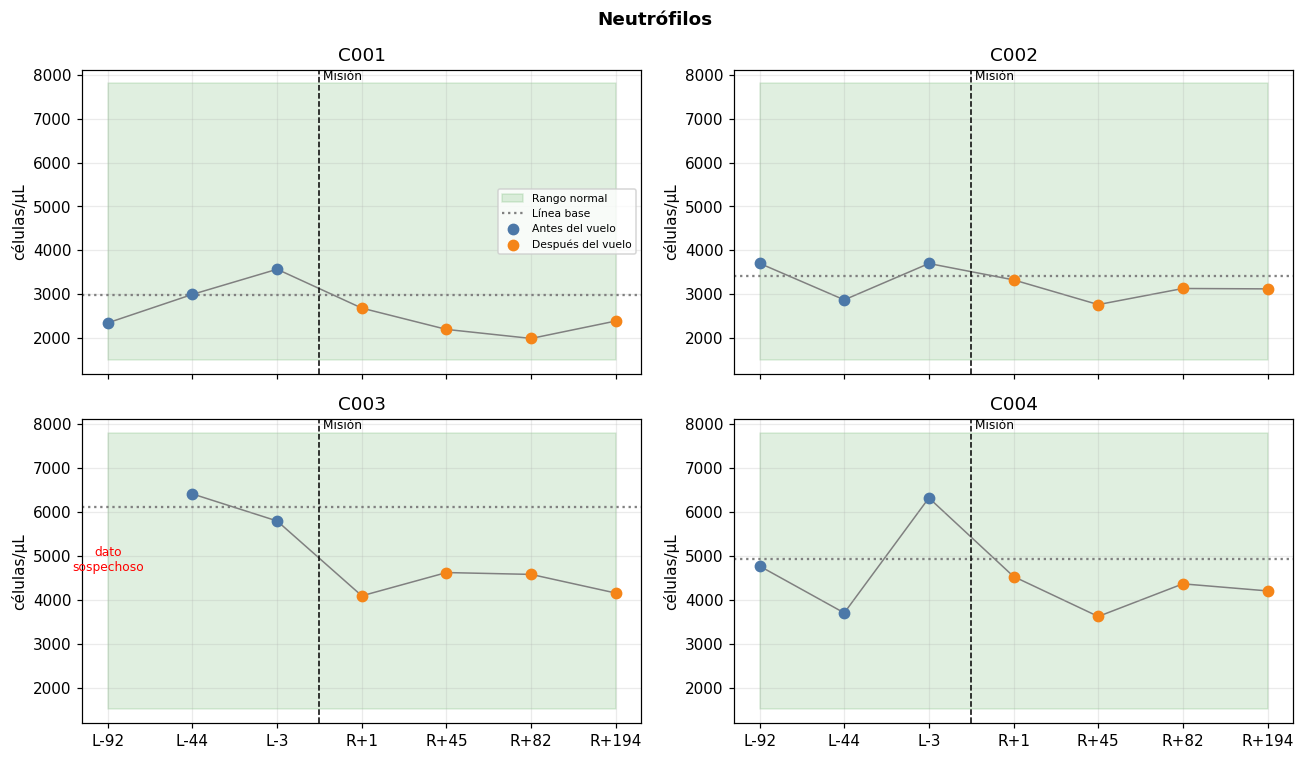

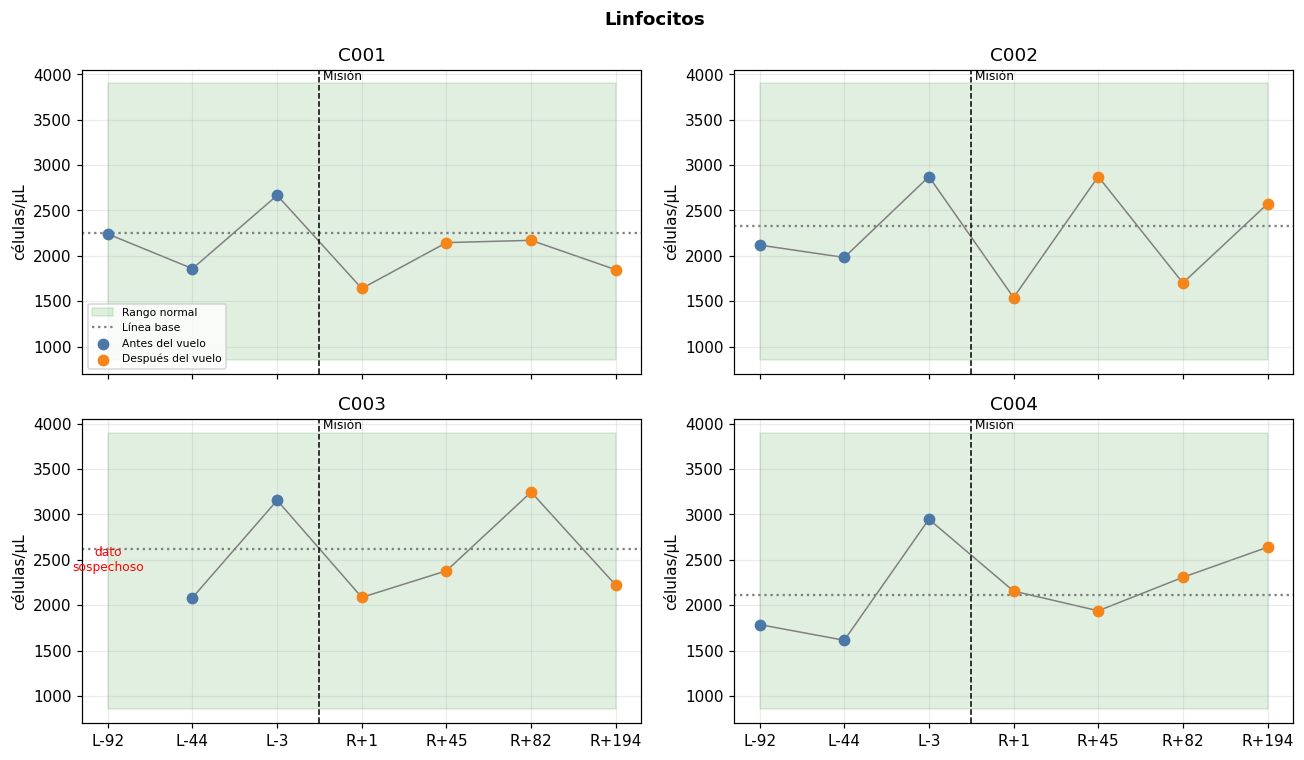

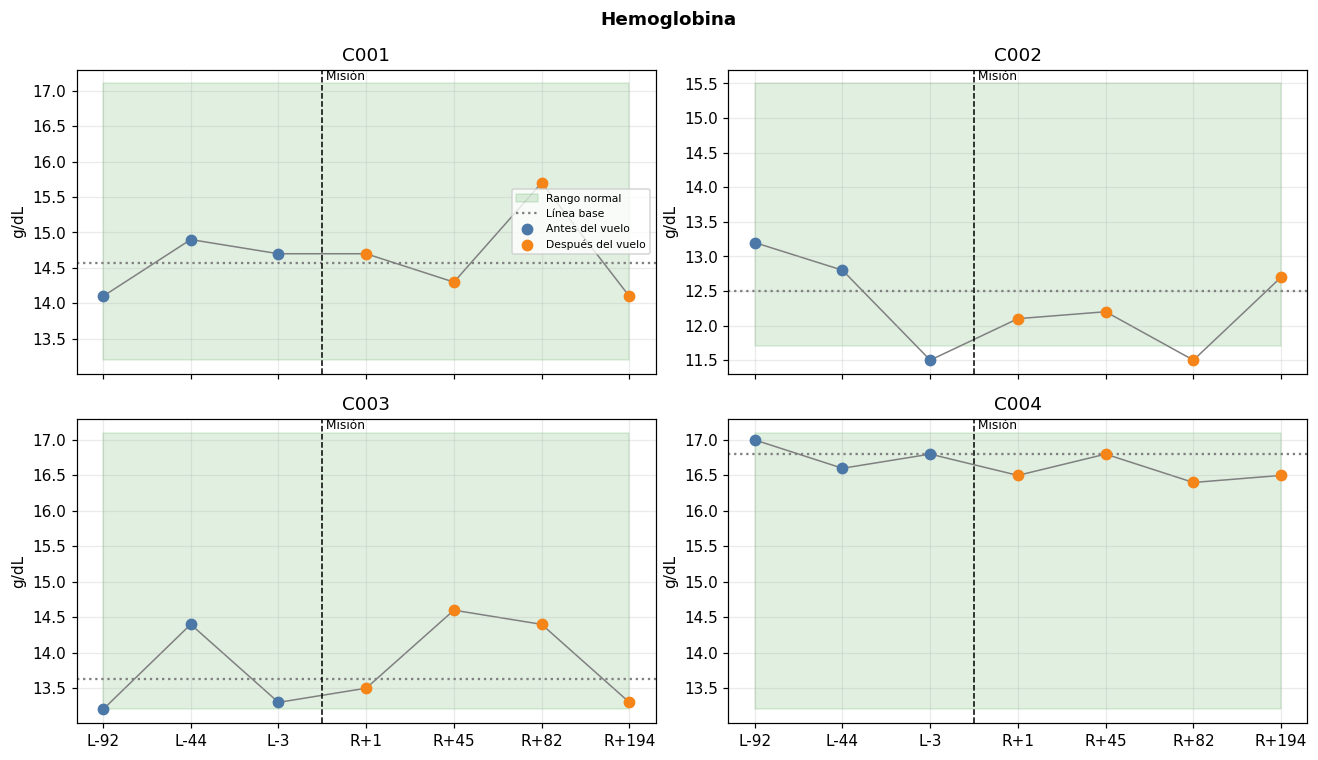

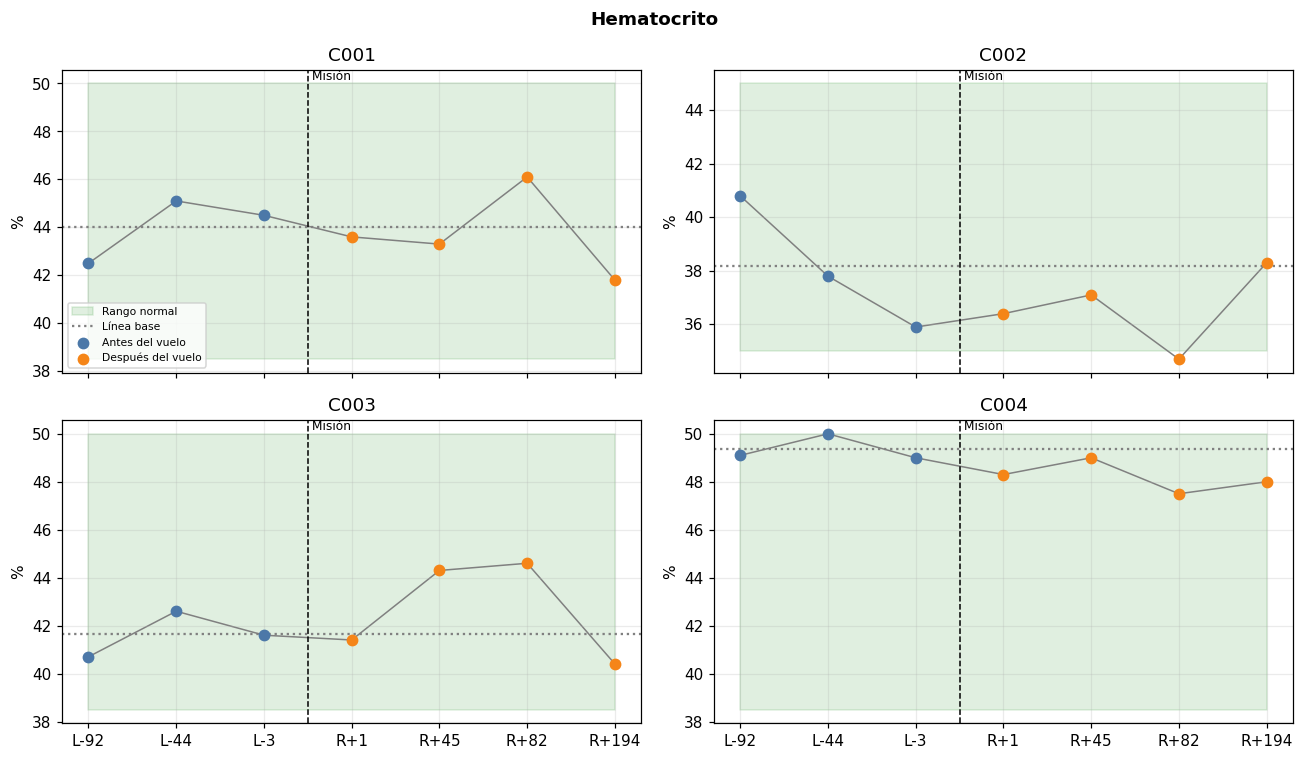

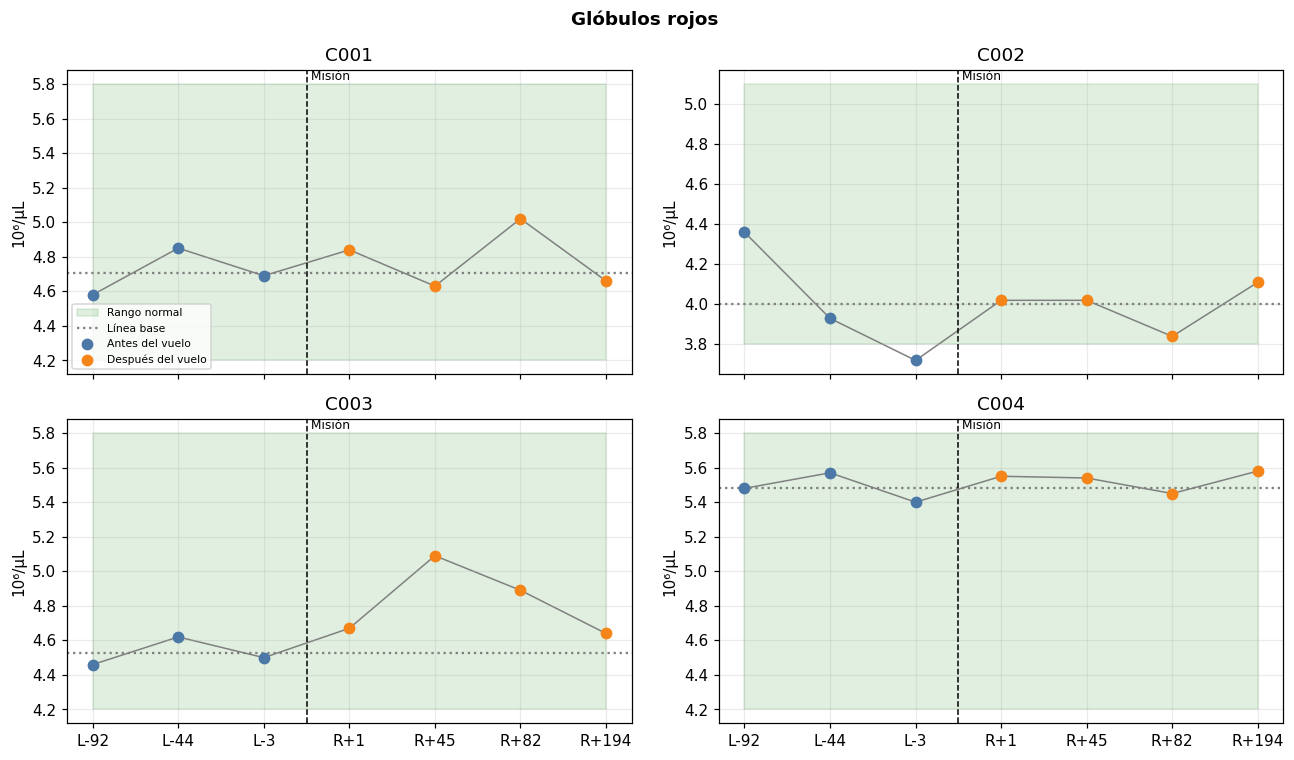

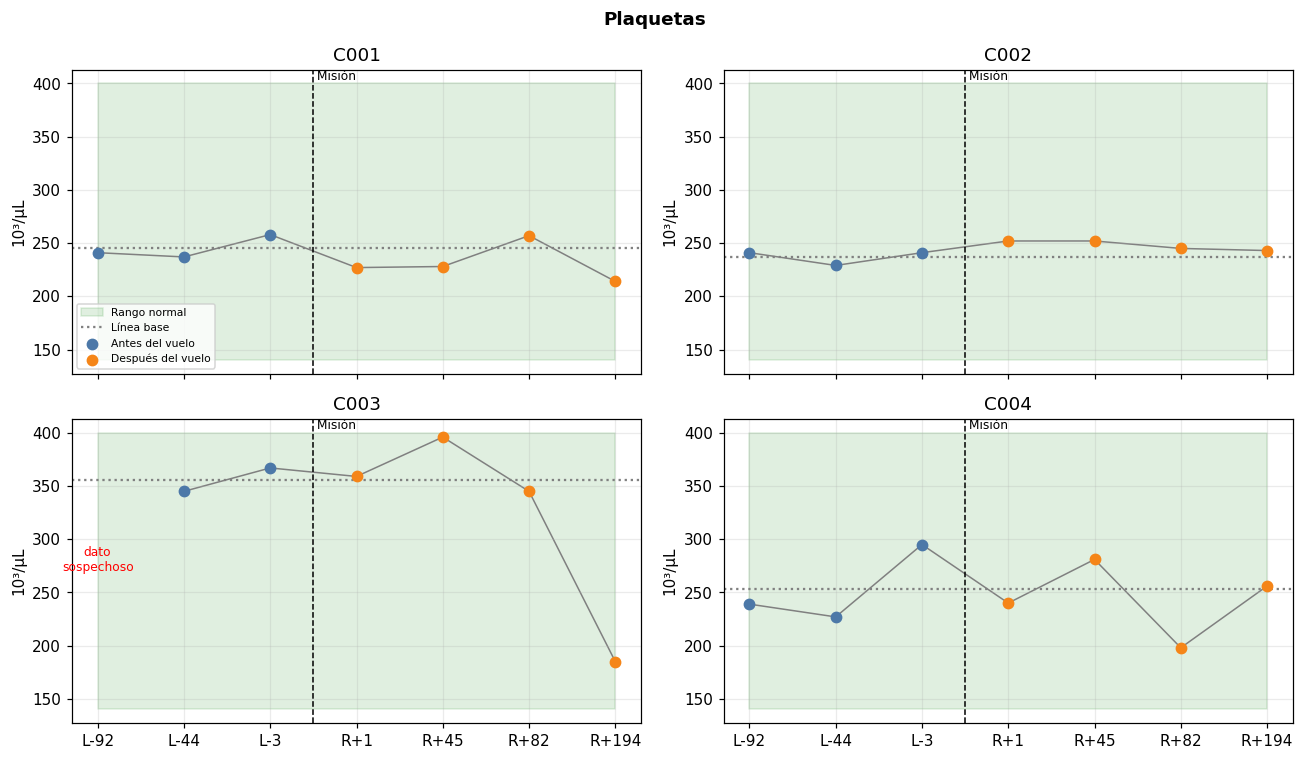

In [44]:
for ab, (nombre, _) in IND.items():
    linea(ab, nombre, UNIDADES[ab], lo=f'{ab}_min', hi=f'{ab}_max',
          base=f'{ab}_base', sosp=ab in SOSP_IND)

### 2.3 Estado vs. rango de laboratorio (Normal / Bajo / Alto)

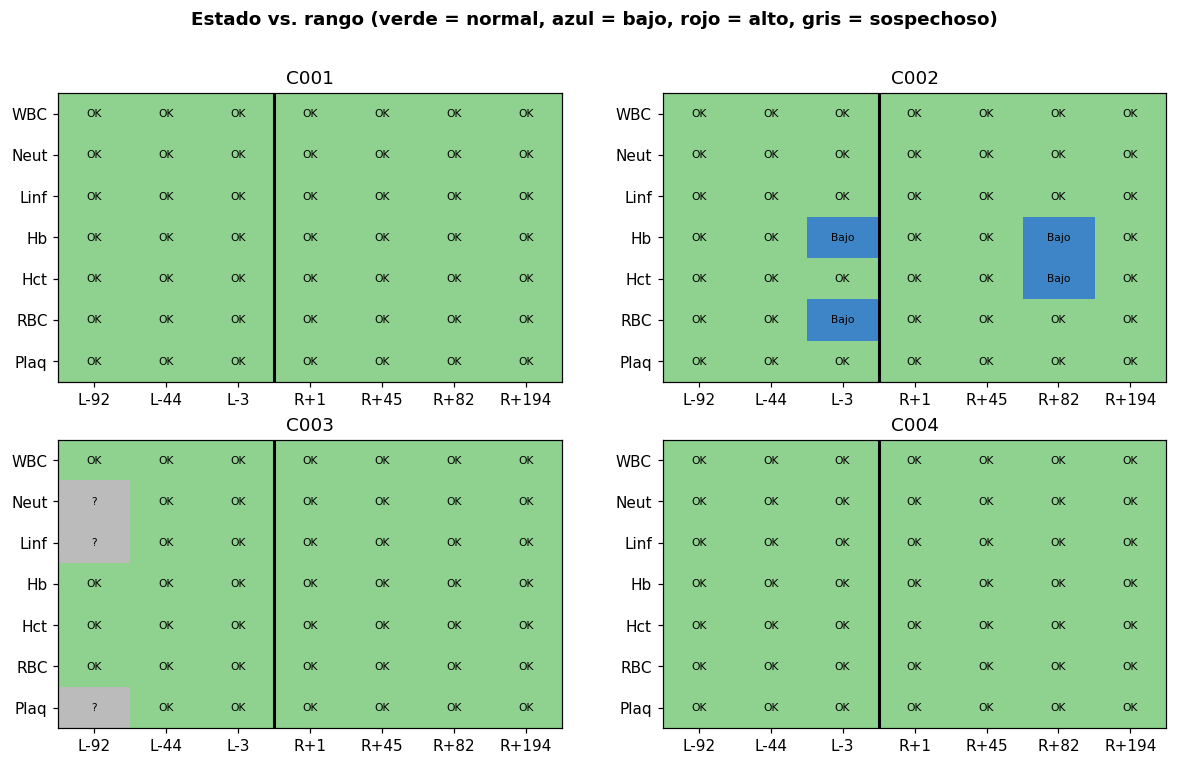

In [45]:
COD = {'Normal': 0, 'Bajo': 1, 'Alto': 2, 'Dato sospechoso': 3}
for ab in IND:
    v, lo, hi = metricas[ab], metricas[f'{ab}_min'], metricas[f'{ab}_max']
    est = np.select([v < lo, v > hi], ['Bajo', 'Alto'], default='Normal')
    metricas[f'{ab}_estado'] = np.where(valido(ab), est, 'Dato sospechoso')
    metricas[f'{ab}_estado_cod'] = metricas[f'{ab}_estado'].map(COD)

cmap = ListedColormap(['#8fd18f', '#3d85c6', '#e4572e', '#bbbbbb'])
mapa('estado_cod', 'Estado vs. rango (verde = normal, azul = bajo, rojo = alto, gris = sospechoso)',
     cmap=cmap, vmin=-.5, vmax=3.5, etiquetas=['OK', 'Bajo', 'Alto', '?'])

### 2.4 Posición en el rango
- 0 = límite inferior
- 0.5 = centro
- 1 = límite superior.

Detecta valores normales pero pegados al borde.

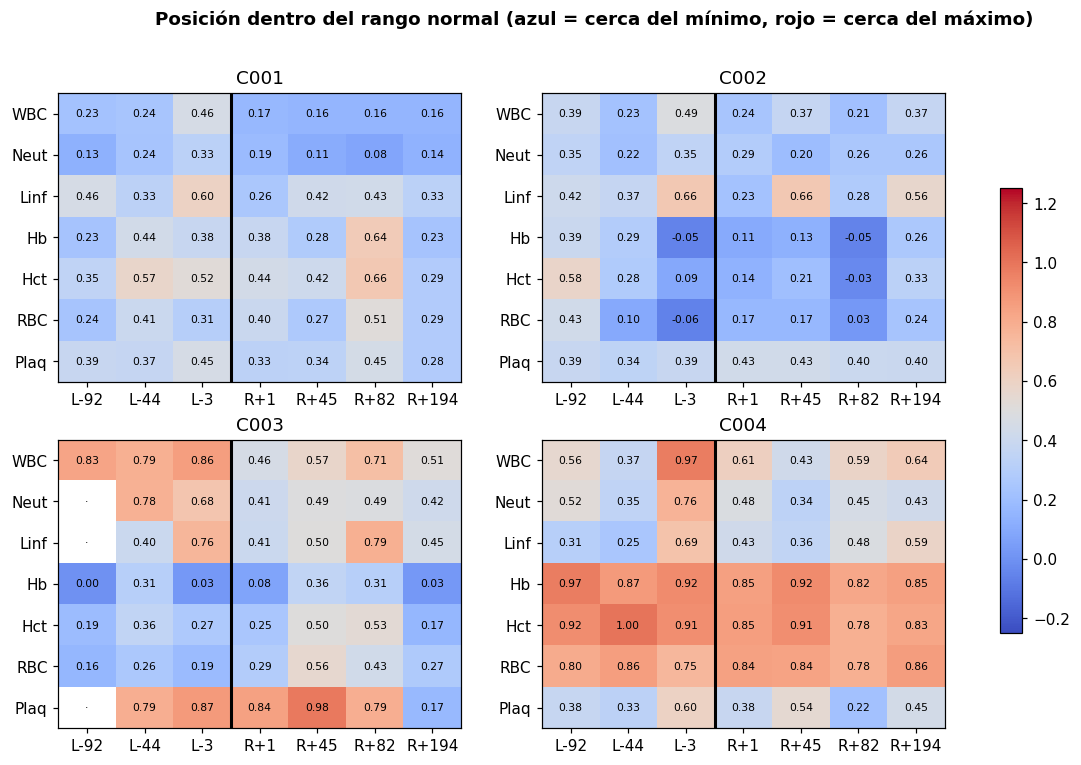

In [46]:
for ab in IND:
    v, lo, hi = metricas[ab], metricas[f'{ab}_min'], metricas[f'{ab}_max']
    pos = ((v - lo) / (hi - lo)).where(valido(ab))
    metricas[f'{ab}_posicion'] = pos
    metricas[f'{ab}_borde'] = (metricas[f'{ab}_estado'] == 'Normal') & ((pos < 0.10) | (pos > 0.90))

mapa('posicion', 'Posición dentro del rango normal (azul = cerca del mínimo, rojo = cerca del máximo)',
     cmap='coolwarm', vmin=-.25, vmax=1.25, fmt='{:.2f}')

### 2.5 Cambio (%) respecto a la línea base personal

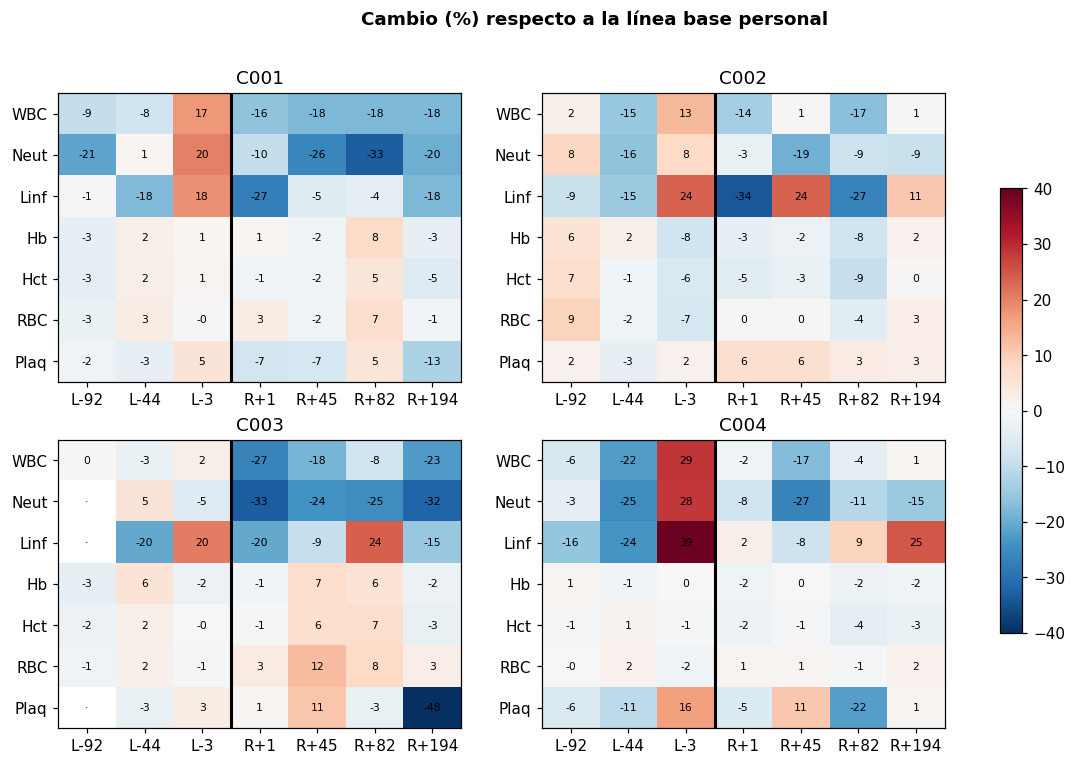

In [47]:
for ab in IND:
    metricas[f'{ab}_cambio_pct'] = ((metricas[ab] - metricas[f'{ab}_base'])
                                    / metricas[f'{ab}_base'] * 100).where(valido(ab))

mapa('cambio_pct', 'Cambio (%) respecto a la línea base personal', vmin=-40, vmax=40)

### 2.6 Z-score personal
Con solo 3 puntos de línea base la SD es inestable.

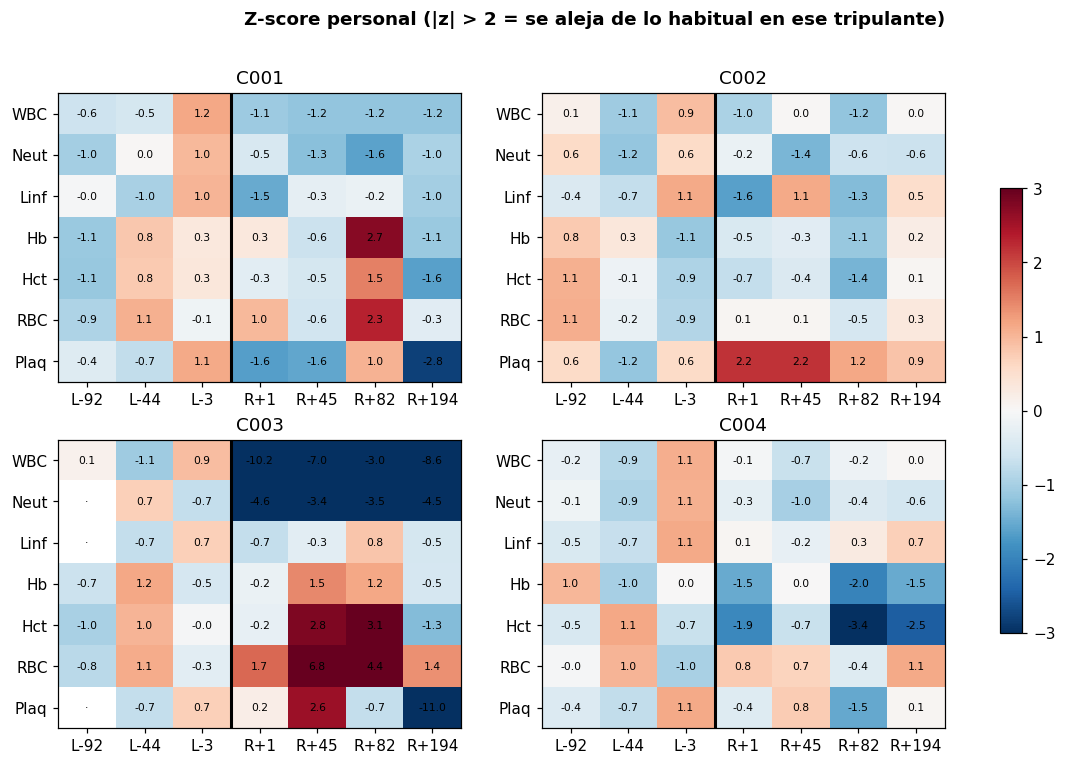

In [48]:
for ab in IND:
    z = (metricas[ab] - metricas[f'{ab}_base']) / metricas[f'{ab}_sd']
    metricas[f'{ab}_z'] = z.replace([np.inf, -np.inf], np.nan).where(valido(ab))

mapa('z', 'Z-score personal (|z| > 2 = se aleja de lo habitual en ese tripulante)',
     vmin=-3, vmax=3, fmt='{:.1f}')

### 2.7 Tendencia post-vuelo (R+1 → R+194)
Pendiente de una recta ajustada a las 4 muestras post-vuelo, en % de la línea base por 100 días. Estable = dentro de ±5%.

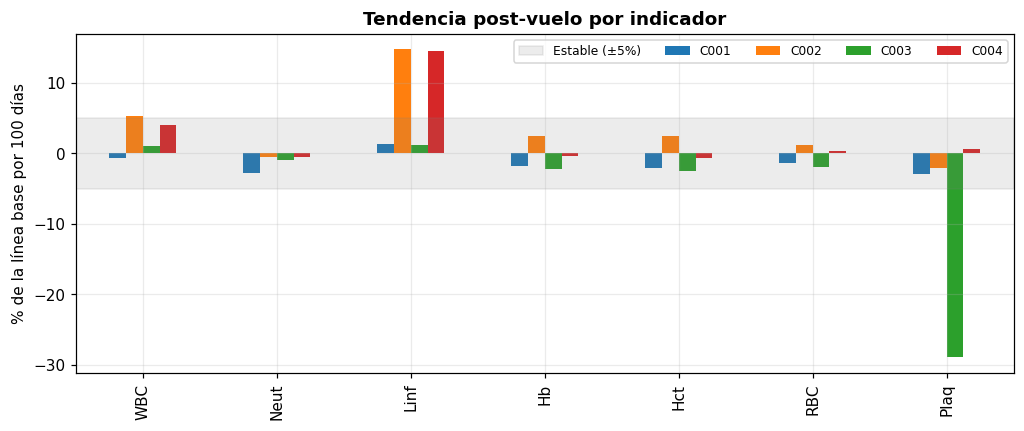

,WBC,Neut,Linf,Hb,Hct,RBC,Plaq
Tripulante,,,,,,,
C001,-0.7,-2.8,1.4,-1.8,-2.1,-1.3,-2.9
C002,5.4,-0.5,14.7,2.5,2.4,1.2,-2.1
C003,1.0,-0.9,1.2,-2.2,-2.5,-1.9,-28.9
C004,4.1,-0.5,14.5,-0.3,-0.6,0.3,0.6


In [49]:
for ab in IND:
    pct = {}
    sel = metricas[post_vuelo & valido(ab) & metricas[ab].notna()]
    for trip, g in sel.groupby('Tripulante'):
        if len(g) >= 3:
            pend = np.polyfit(g['Días'], g[ab], 1)[0]                 # unidades por día
            pct[trip] = pend * 100 / g[f'{ab}_base'].iloc[0] * 100    # % de la línea base por 100 días
    s = metricas['Tripulante'].map(pct).astype(float)
    metricas[f'{ab}_pend_pct100d'] = s.where(post_vuelo)
    etq = np.select([s.isna(), s.abs() < 5, s > 0], ['N/D', 'Estable', 'Sube'], default='Baja')
    metricas[f'{ab}_tendencia'] = pd.Series(etq, index=metricas.index).where(post_vuelo)

tend = metricas[metricas['Días'] == 194].set_index('Tripulante')[[f'{ab}_pend_pct100d' for ab in IND]]
tend.columns = list(IND)
ax = tend.T.plot.bar(figsize=(11, 4))
ax.axhspan(-5, 5, color='gray', alpha=.15, label='Estable (±5%)')
ax.set_ylabel('% de la línea base por 100 días'); ax.set_title('Tendencia post-vuelo por indicador', fontweight='bold')
ax.legend(ncol=5, fontsize=8); plt.show()
tend.round(1)

## 3. Indicadores derivados

### 3.1 NLR (neutrófilos / linfocitos)
Marcador de estrés fisiológico e inflamación. Sube con el estrés y baja con la recuperación.

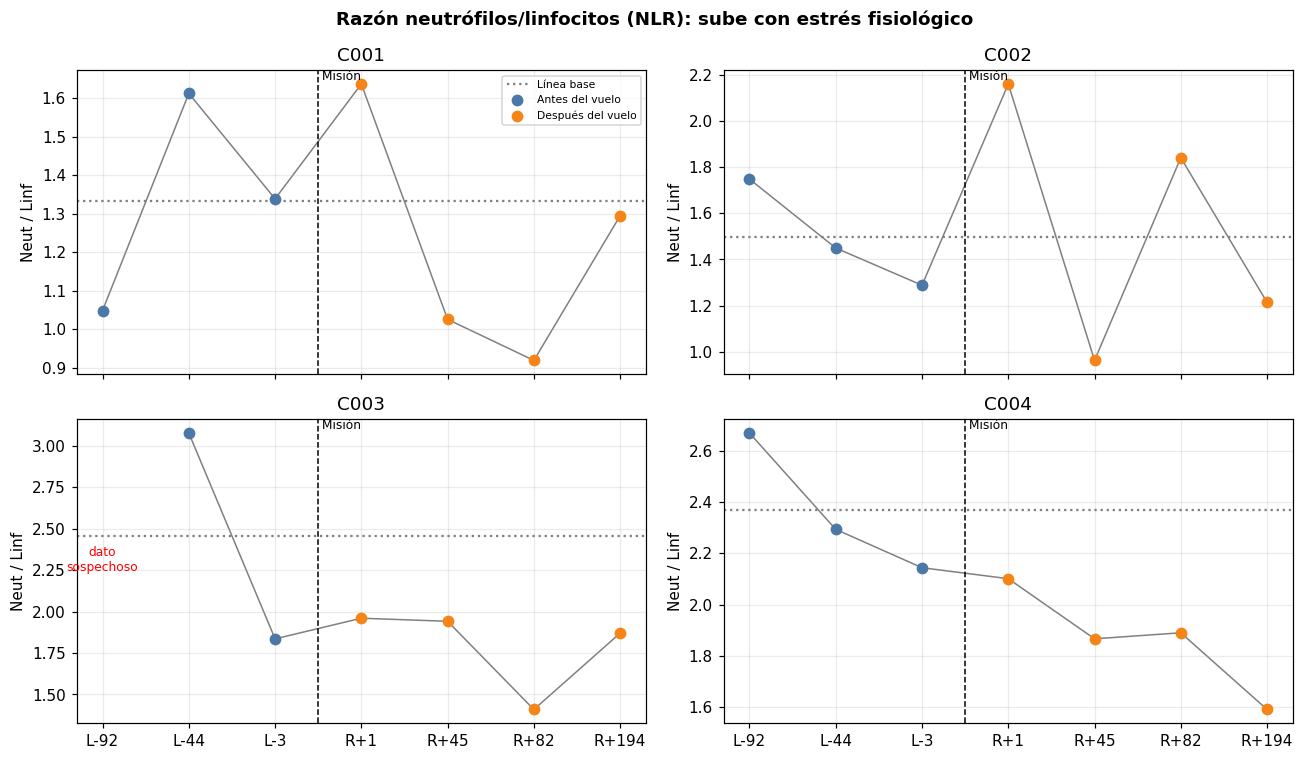

(<Figure size 1320x770 with 4 Axes>,
 array([[<Axes: title={'center': 'C001'}, ylabel='Neut / Linf'>,
         <Axes: title={'center': 'C002'}, ylabel='Neut / Linf'>],
        [<Axes: title={'center': 'C003'}, ylabel='Neut / Linf'>,
         <Axes: title={'center': 'C004'}, ylabel='Neut / Linf'>]],
       dtype=object))

In [50]:
metricas['NLR'] = (metricas['Neut'] / metricas['Linf']).where(~es_sosp)
metricas['NLR_base'], _ = base_pre(metricas['NLR'])
metricas['NLR_cambio_pct'] = (metricas['NLR'] - metricas['NLR_base']) / metricas['NLR_base'] * 100

linea('NLR', 'Razón neutrófilos/linfocitos (NLR): sube con estrés fisiológico', 'Neut / Linf',
      base='NLR_base', sosp=True)

### 3.2 % de neutrófilos y % de linfocitos (fórmula leucocitaria)

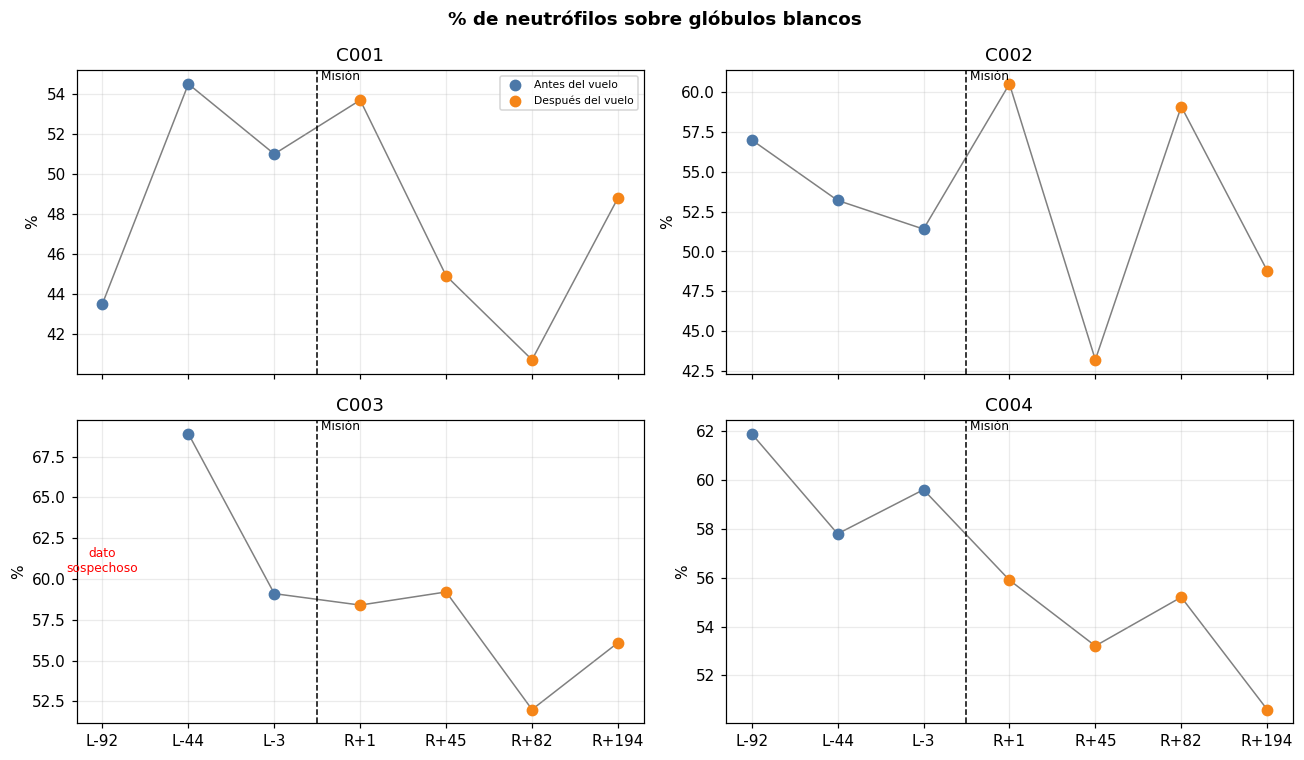

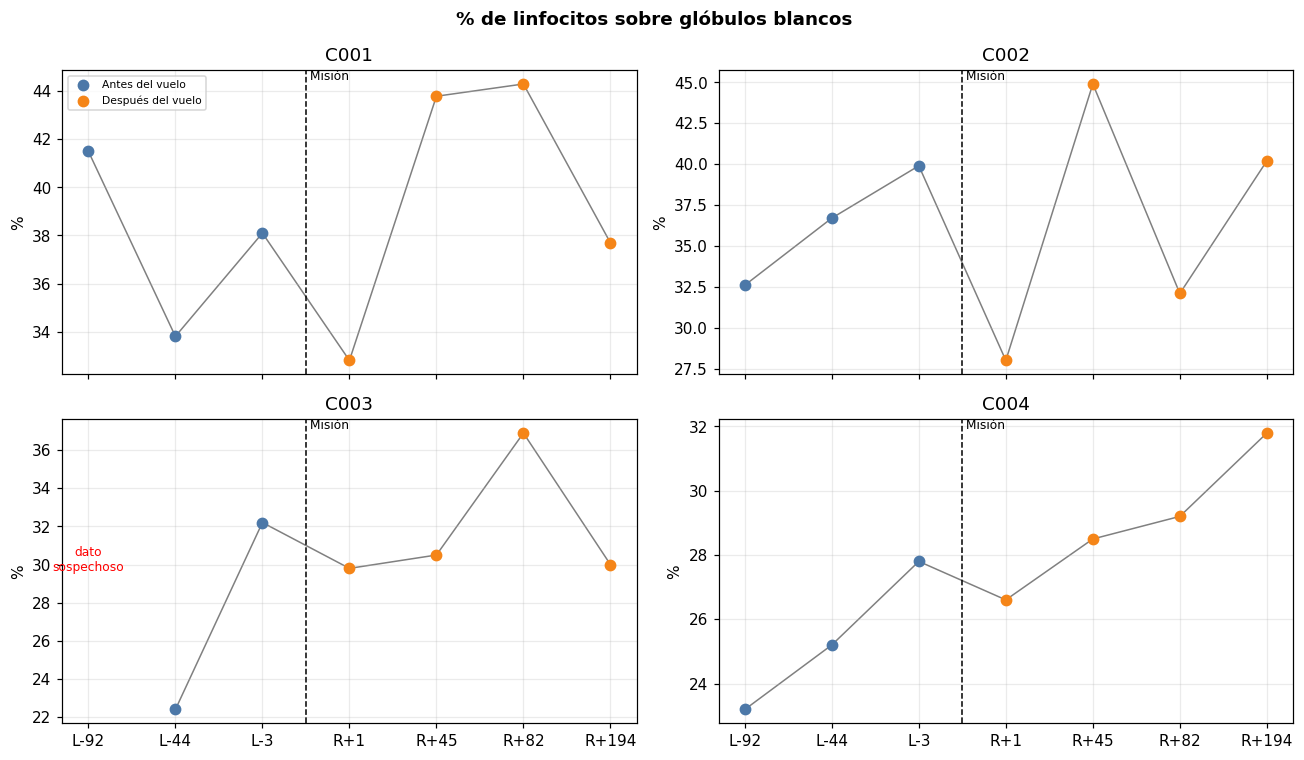

(<Figure size 1320x770 with 4 Axes>,
 array([[<Axes: title={'center': 'C001'}, ylabel='%'>,
         <Axes: title={'center': 'C002'}, ylabel='%'>],
        [<Axes: title={'center': 'C003'}, ylabel='%'>,
         <Axes: title={'center': 'C004'}, ylabel='%'>]], dtype=object))

In [51]:
metricas['Pct_Neut'] = (metricas['Neut'] / (metricas['WBC'] * 1000) * 100).where(~es_sosp)
metricas['Pct_Linf'] = (metricas['Linf'] / (metricas['WBC'] * 1000) * 100).where(~es_sosp)

linea('Pct_Neut', '% de neutrófilos sobre glóbulos blancos', '%', sosp=True)
linea('Pct_Linf', '% de linfocitos sobre glóbulos blancos', '%', sosp=True)

### 3.3 MCV estimado (fL)
Tamaño del glóbulo rojo. Banda 80 a 100 fL = límites convencionales.

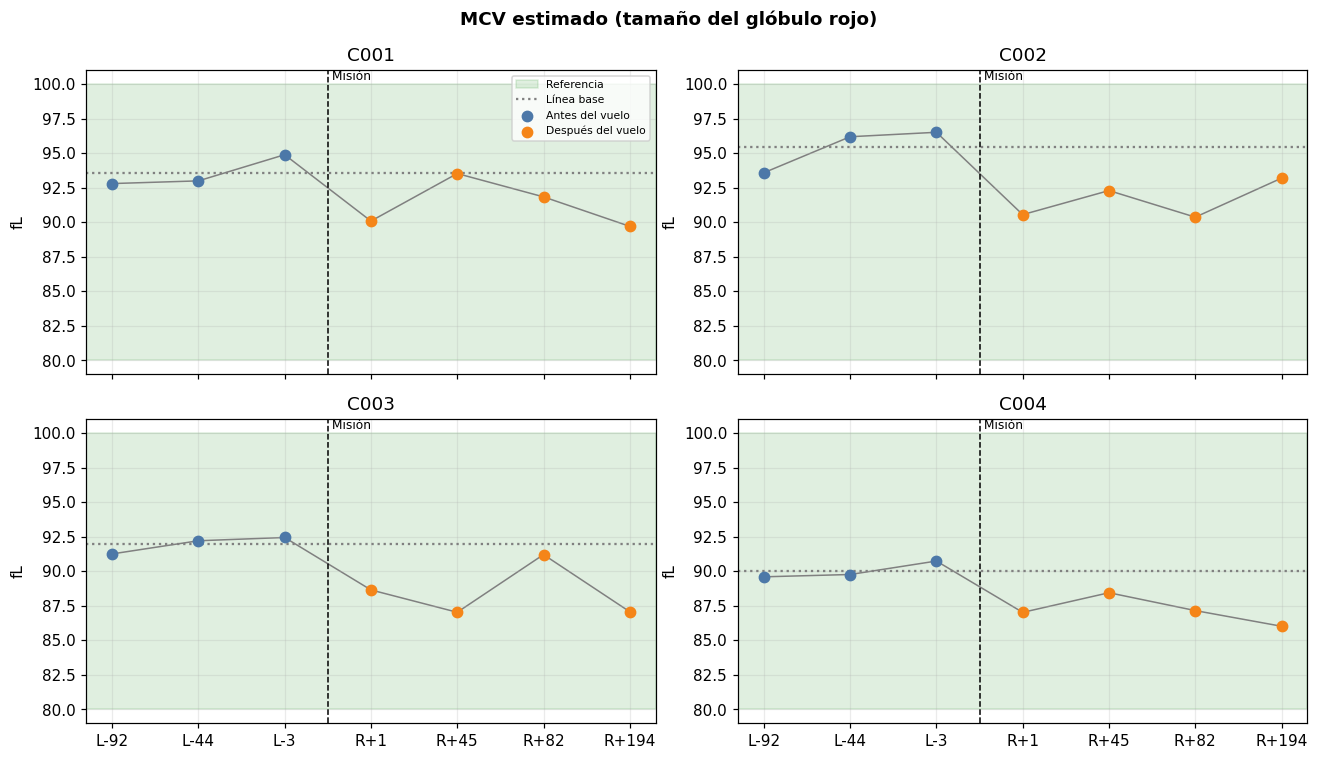

(<Figure size 1320x770 with 4 Axes>,
 array([[<Axes: title={'center': 'C001'}, ylabel='fL'>,
         <Axes: title={'center': 'C002'}, ylabel='fL'>],
        [<Axes: title={'center': 'C003'}, ylabel='fL'>,
         <Axes: title={'center': 'C004'}, ylabel='fL'>]], dtype=object))

In [52]:
metricas['MCV_est'] = metricas['Hct'] / metricas['RBC'] * 10
metricas['MCV_base'], _ = base_pre(metricas['MCV_est'])
metricas['MCV_cambio_pct'] = (metricas['MCV_est'] - metricas['MCV_base']) / metricas['MCV_base'] * 100

linea('MCV_est', 'MCV estimado (tamaño del glóbulo rojo)', 'fL', base='MCV_base', banda=(80, 100))

### 3.4 MCH y MCHC estimados

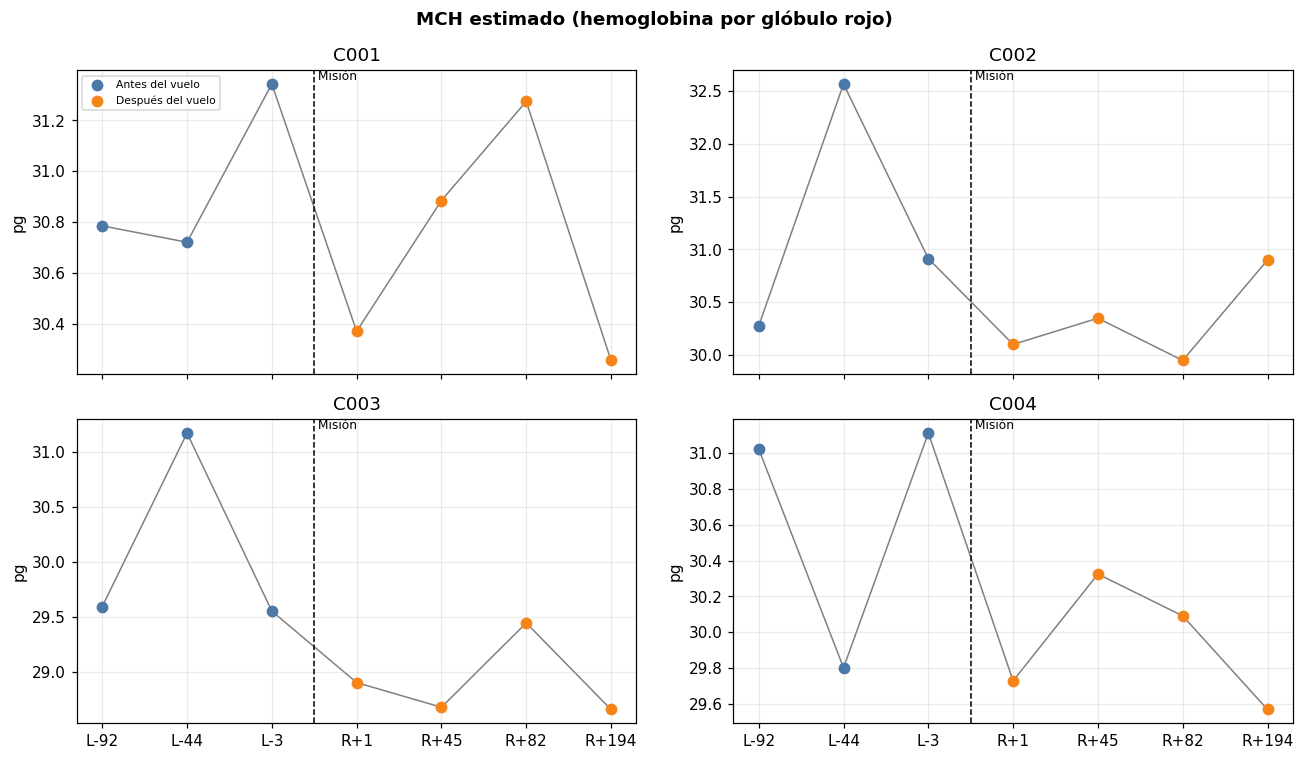

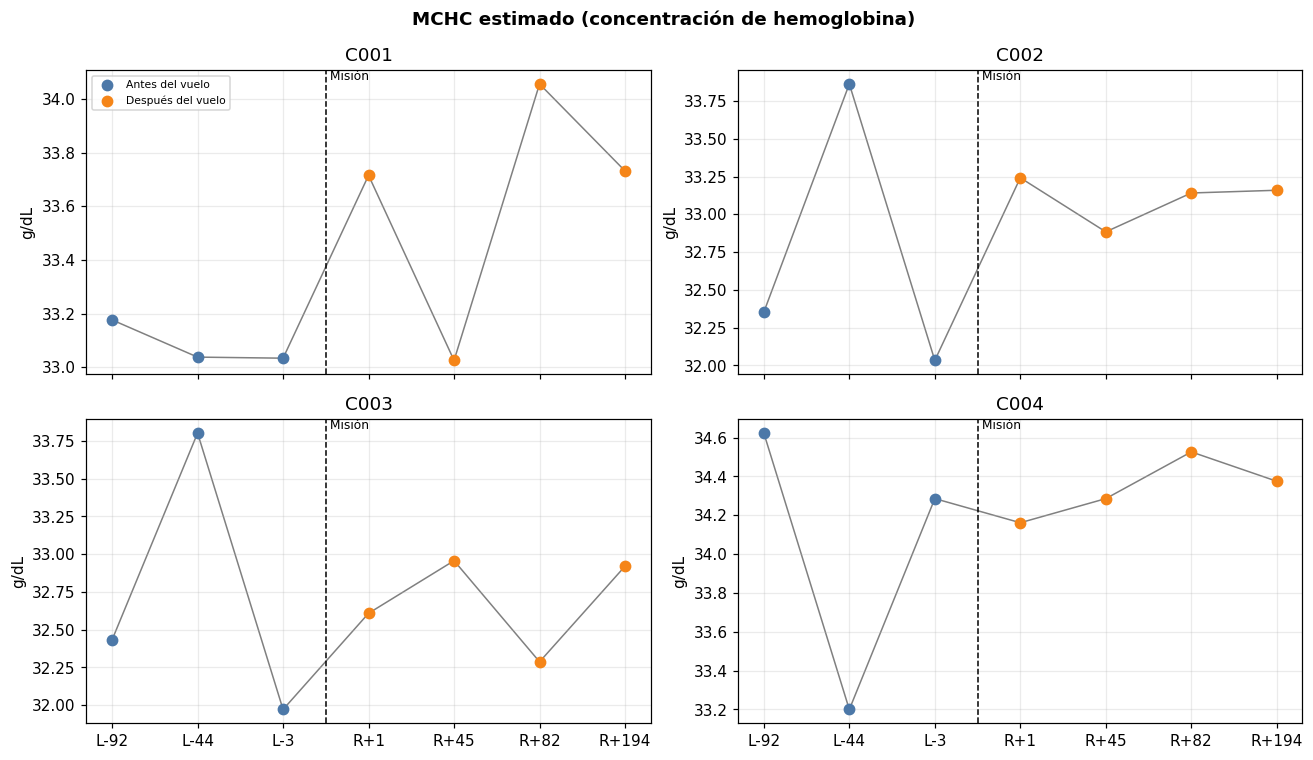

(<Figure size 1320x770 with 4 Axes>,
 array([[<Axes: title={'center': 'C001'}, ylabel='g/dL'>,
         <Axes: title={'center': 'C002'}, ylabel='g/dL'>],
        [<Axes: title={'center': 'C003'}, ylabel='g/dL'>,
         <Axes: title={'center': 'C004'}, ylabel='g/dL'>]], dtype=object))

In [53]:
metricas['MCH_est']  = metricas['Hb'] / metricas['RBC'] * 10     # pg
metricas['MCHC_est'] = metricas['Hb'] / metricas['Hct'] * 100    # g/dL

linea('MCH_est', 'MCH estimado (hemoglobina por glóbulo rojo)', 'pg')
linea('MCHC_est', 'MCHC estimado (concentración de hemoglobina)', 'g/dL')

### 3.5 Cambio de volumen plasmático (Dill y Costill, solo post-vuelo)
Negativo = hemoconcentración (menos plasma). Es una estimación pensada para cambios agudos.

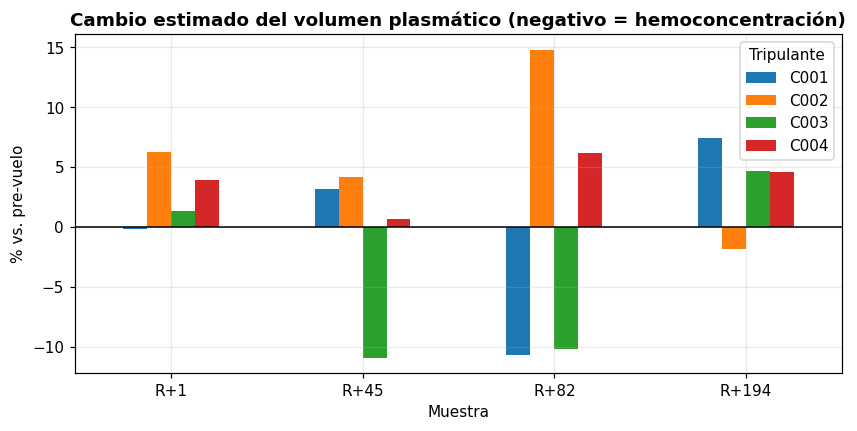

Tripulante,C001,C002,C003,C004
Muestra,,,,
R+1,-0.1,6.3,1.4,4.0
R+45,3.2,4.2,-10.9,0.7
R+82,-10.6,14.8,-10.1,6.2
R+194,7.4,-1.8,4.7,4.6


In [54]:
dvp = 100 * ((metricas['Hb_base'] / metricas['Hb']) *
             ((100 - metricas['Hct']) / (100 - metricas['Hct_base'])) - 1)
metricas['Cambio_VP_pct'] = dvp.where(post_vuelo)

vp = (metricas[post_vuelo].pivot(index='Muestra', columns='Tripulante', values='Cambio_VP_pct')
      .loc[['R+1', 'R+45', 'R+82', 'R+194']])
ax = vp.plot.bar(figsize=(9, 4)); ax.axhline(0, color='k', lw=1)
ax.set_ylabel('% vs. pre-vuelo')
ax.set_title('Cambio estimado del volumen plasmático (negativo = hemoconcentración)', fontweight='bold')
plt.xticks(rotation=0); plt.show()
vp.round(1)

### 3.6 Control de calidad: Hct ≈ 3 × Hb

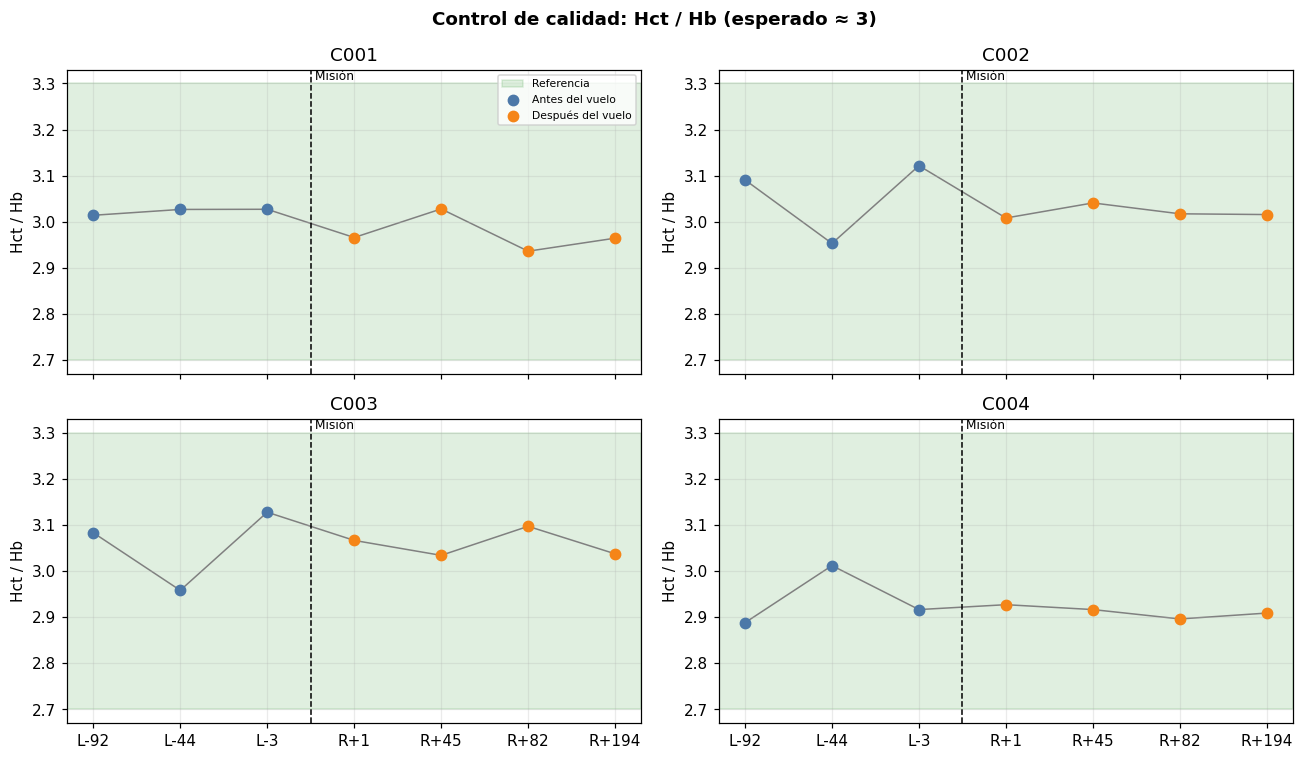

,count
Control_Hct_Hb,
OK,28


In [55]:
metricas['Hct_sobre_Hb'] = metricas['Hct'] / metricas['Hb']
metricas['Control_Hct_Hb'] = np.where(metricas['Hct_sobre_Hb'].between(2.7, 3.3), 'OK', 'Revisar')

linea('Hct_sobre_Hb', 'Control de calidad: Hct / Hb (esperado ≈ 3)', 'Hct / Hb', banda=(2.7, 3.3))
metricas['Control_Hct_Hb'].value_counts()

## 4. Anemia (por Fase de Vuelo y Días)


### 4.1 Anemia por muestra
- **Anemia:** hemoglobina bajo el límite inferior del tripulante.
- **Sospecha:** hematocrito o glóbulos rojos bajos con hemoglobina normal.

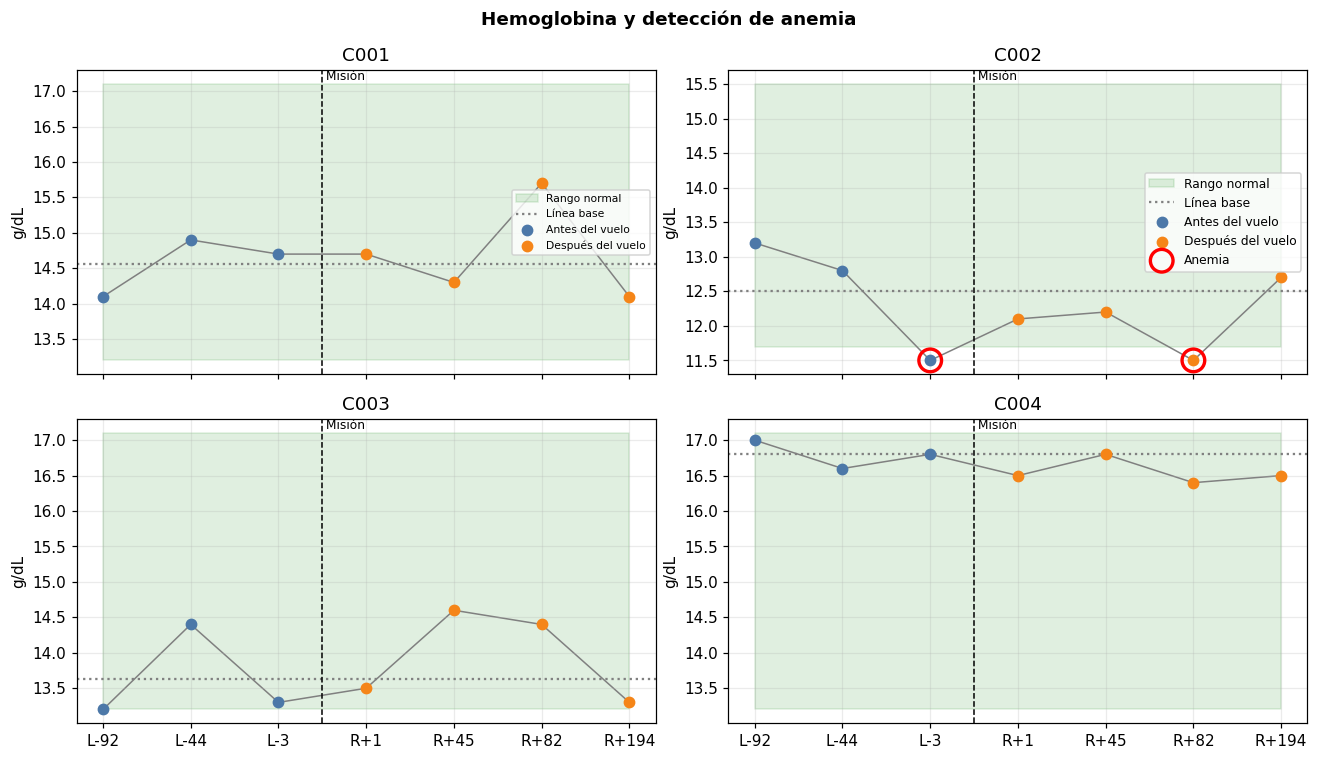

,Tripulante,Fase de Vuelo,Muestra,Hb,Hb_min,Hct,RBC,Anemia_muestra,Anemia_deficit_Hb,Anemia_criterios
9,C002,Antes del Vuelo,L-3,11.5,11.7,35.9,3.72,Anemia,0.2,2
12,C002,Después del Vuelo,R+82,11.5,11.7,34.7,3.84,Anemia,0.2,2


In [56]:
hb_bajo  = metricas['Hb_estado']  == 'Bajo'
hct_bajo = metricas['Hct_estado'] == 'Bajo'
rbc_bajo = metricas['RBC_estado'] == 'Bajo'

metricas['Anemia_muestra'] = np.select([hb_bajo, hct_bajo | rbc_bajo], ['Anemia', 'Sospecha'], default='Sin anemia')
metricas['Anemia_deficit_Hb'] = (metricas['Hb_min'] - metricas['Hb']).where(hb_bajo).round(2)
metricas['Anemia_criterios'] = hb_bajo.astype(int) + hct_bajo.astype(int) + rbc_bajo.astype(int)

fig, axes = linea('Hb', 'Hemoglobina y detección de anemia', 'g/dL', lo='Hb_min', hi='Hb_max',
                  base='Hb_base', show=False)
for ax, t in zip(axes.ravel(), TRIPS):
    d = _sub(t)
    for est, color in {'Anemia': 'red', 'Sospecha': 'orange'}.items():
        m = (d['Anemia_muestra'] == est).values
        if m.any():
            ax.scatter(np.where(m)[0], d.loc[m, 'Hb'], s=220, facecolors='none',
                       edgecolors=color, linewidths=2.2, zorder=4, label=est)
axes.ravel()[1].legend(fontsize=8)
plt.show()

metricas.loc[metricas['Anemia_muestra'] != 'Sin anemia',
             ['Tripulante', 'Fase de Vuelo', 'Muestra', 'Hb', 'Hb_min', 'Hct', 'RBC',
              'Anemia_muestra', 'Anemia_deficit_Hb', 'Anemia_criterios']]

### 4.2 Tipo de anemia según el MCV estimado

In [57]:
mcv = metricas['MCV_est']
tipo = np.select([mcv < 80, mcv > 100], ['Microcítica', 'Macrocítica'], default='Normocítica')
metricas['Anemia_tipo'] = np.where(metricas['Anemia_muestra'] == 'Anemia', tipo, '—')

metricas.loc[metricas['Anemia_muestra'] == 'Anemia',
             ['Tripulante', 'Fase de Vuelo', 'Muestra', 'Hb', 'MCV_est', 'Anemia_tipo']].round(1)

,Tripulante,Fase de Vuelo,Muestra,Hb,MCV_est,Anemia_tipo
9,C002,Antes del Vuelo,L-3,11.5,96.5,Normocítica
12,C002,Después del Vuelo,R+82,11.5,90.4,Normocítica


### 4.3 Anemia por tripulante: ¿antes del vuelo, después, o ambos?

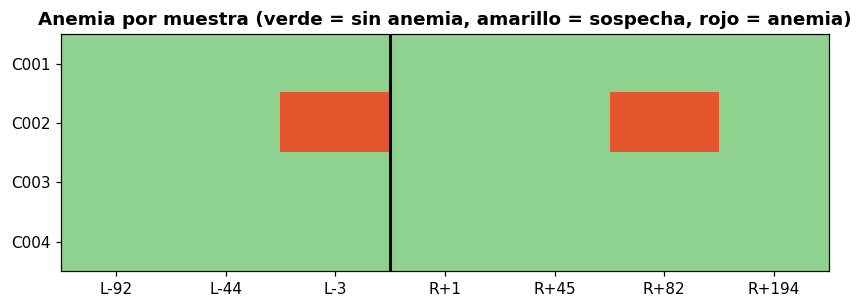

,Tripulante,Anemia_perfil,Anemia_muestras
0,C001,Sin anemia,—
1,C002,Pre y post-vuelo,"L-3, R+82"
2,C003,Sin anemia,—
3,C004,Sin anemia,—


In [58]:
an = metricas['Anemia_muestra'] == 'Anemia'
g = metricas['Tripulante']
metricas['Anemia_pre']  = (an & pre_vuelo).groupby(g).transform('any')
metricas['Anemia_post'] = (an & post_vuelo).groupby(g).transform('any')
metricas['Anemia_perfil'] = np.select(
    [metricas['Anemia_pre'] & metricas['Anemia_post'], metricas['Anemia_pre'], metricas['Anemia_post']],
    ['Pre y post-vuelo', 'Solo pre-vuelo', 'Solo post-vuelo (aparición nueva)'], default='Sin anemia')
metricas['Anemia_muestras'] = metricas['Tripulante'].map(
    metricas[an].groupby('Tripulante')['Muestra'].apply(', '.join)).fillna('—')

cod = metricas['Anemia_muestra'].map({'Sin anemia': 0, 'Sospecha': 1, 'Anemia': 2})
mat = metricas.assign(cod=cod).pivot(index='Tripulante', columns='Días', values='cod')
etq = metricas.drop_duplicates('Días').sort_values('Días')['Muestra'].tolist()
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.imshow(mat.values.astype(float), cmap=ListedColormap(['#8fd18f', '#f2c14e', '#e4572e']), vmin=-.5, vmax=2.5, aspect='auto')
ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels(etq)
ax.set_yticks(range(mat.shape[0])); ax.set_yticklabels(mat.index)
ax.axvline(2.5, color='k', lw=2); ax.grid(False)
ax.set_title('Anemia por muestra (verde = sin anemia, amarillo = sospecha, rojo = anemia)', fontweight='bold')
plt.show()

metricas[['Tripulante', 'Anemia_perfil', 'Anemia_muestras']].drop_duplicates().reset_index(drop=True)

## 5. Indicadores ligados a los objetivos del reto
Parámetros del semáforo. **Los umbrales son propuestas de trabajo, no criterios clínicos:** ajústalos o justifícalos con NASA HRP o literatura médica.

In [59]:
# cambio % vs línea base personal -> (umbral amarillo, umbral rojo)
UMBRAL_CAMBIO = {'WBC': (25, 50), 'Neut': (30, 60), 'Linf': (25, 50), 'Hb': (8, 15),
                 'Hct': (8, 15), 'RBC': (8, 15), 'Plaq': (20, 40)}
UMBRAL_NLR = (50, 100)    # aumento % vs línea base
UMBRAL_VP  = (10, 20)     # |cambio de volumen plasmático| %
print('Umbrales de cambio %:', UMBRAL_CAMBIO, '| NLR:', UMBRAL_NLR, '| VP:', UMBRAL_VP)


Umbrales de cambio %: {'WBC': (25, 50), 'Neut': (30, 60), 'Linf': (25, 50), 'Hb': (8, 15), 'Hct': (8, 15), 'RBC': (8, 15), 'Plaq': (20, 40)} | NLR: (50, 100) | VP: (10, 20)


### 5.1 Semáforo por indicador
Se toma el peor de cuatro criterios:
- **Rango:** fuera por hasta 10% del ancho del rango = amarillo, más = rojo.
- **Borde:** normal pero en el 10% extremo del rango = amarillo.
- **Cambio % vs. línea base:** según `UMBRAL_CAMBIO`.
- **z-score:** |z| ≥ 2 cuenta solo si el cambio es al menos la mitad del umbral amarillo.

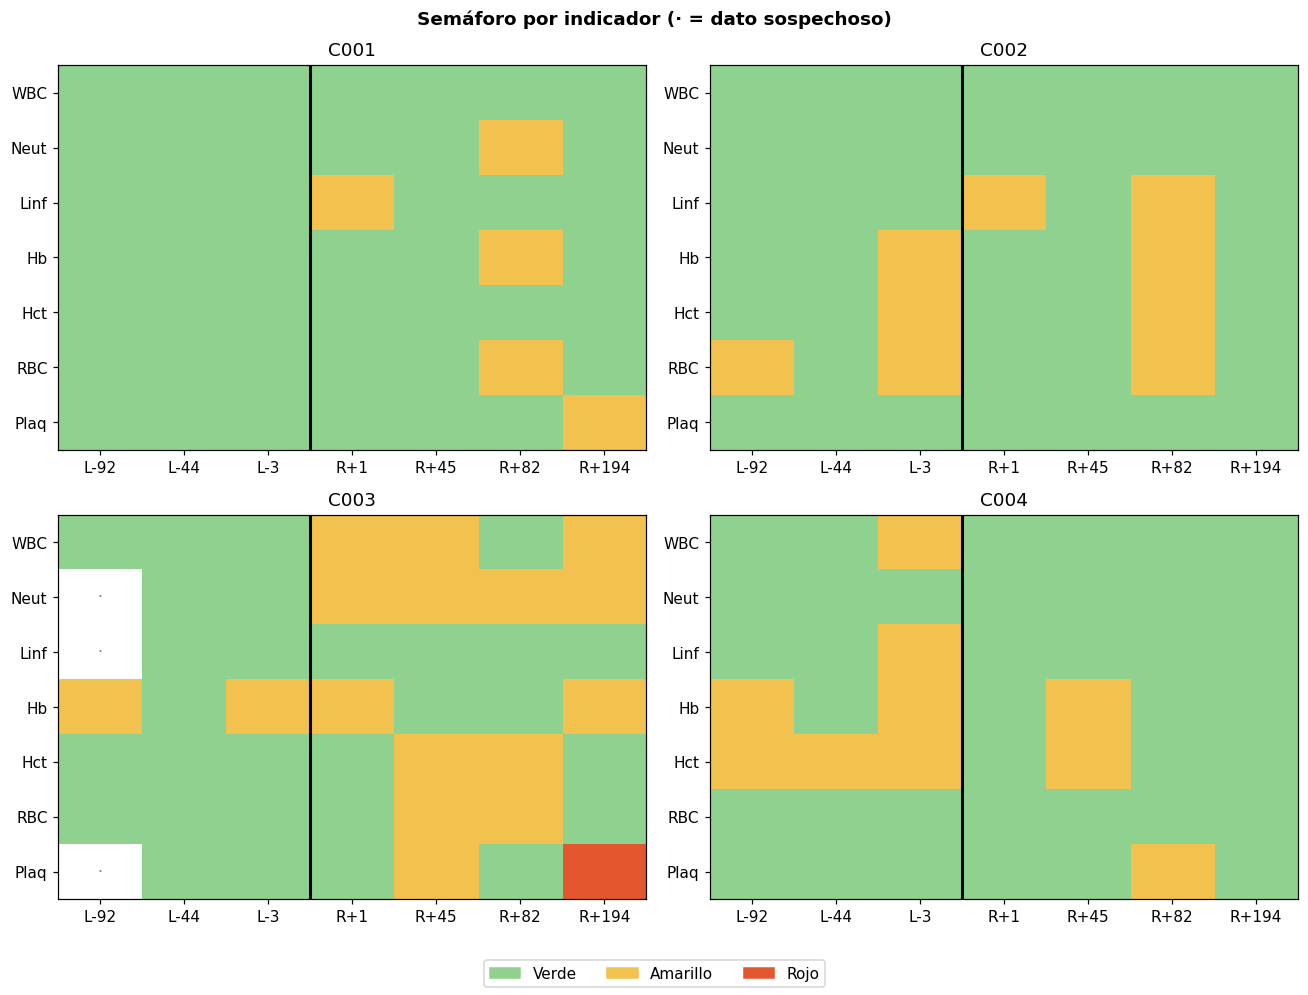

In [60]:
for ab in IND:
    estado = metricas[f'{ab}_estado']
    v, lo, hi = metricas[ab], metricas[f'{ab}_min'], metricas[f'{ab}_max']
    dist = np.asarray(np.where(estado == 'Bajo', lo - v, np.where(estado == 'Alto', v - hi, 0)) / (hi - lo), dtype=float)
    s_rango = np.select([np.asarray(estado == 'Normal'), dist <= 0.10], [0, 1], default=2)
    s_borde = metricas[f'{ab}_borde'].astype(int).values
    ca, cr = UMBRAL_CAMBIO[ab]
    c = metricas[f'{ab}_cambio_pct'].abs().values
    s_cambio = np.select([c >= cr, c >= ca], [2, 1], default=0)
    s_z = ((metricas[f'{ab}_z'].abs().values >= 2) & (c >= ca / 2)).astype(int)
    sem = pd.Series(np.maximum.reduce([s_rango, s_borde, s_cambio, s_z]), index=metricas.index)
    metricas[f'{ab}_sem'] = sem.where(estado != 'Dato sospechoso')

mapa_sem([f'{ab}_sem' for ab in IND], list(IND), 'Semáforo por indicador (· = dato sospechoso)')

### 5.2 Estrés inmune (NLR vs. línea base)
El NLR no tiene rango de laboratorio: se evalúa por su aumento respecto a la línea base.

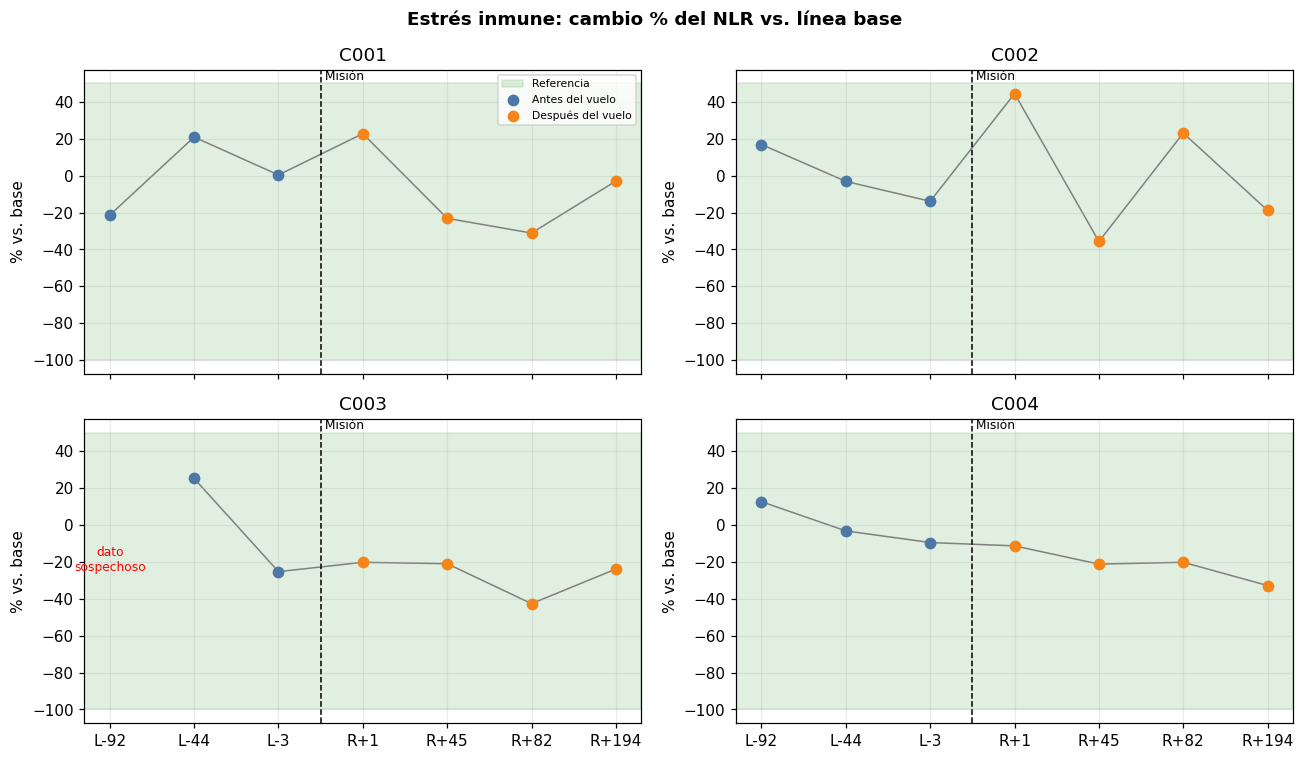

(<Figure size 1320x770 with 4 Axes>,
 array([[<Axes: title={'center': 'C001'}, ylabel='% vs. base'>,
         <Axes: title={'center': 'C002'}, ylabel='% vs. base'>],
        [<Axes: title={'center': 'C003'}, ylabel='% vs. base'>,
         <Axes: title={'center': 'C004'}, ylabel='% vs. base'>]],
       dtype=object))

In [61]:
c = metricas['NLR_cambio_pct']
metricas['NLR_sem'] = pd.Series(np.select([c >= UMBRAL_NLR[1], c >= UMBRAL_NLR[0]], [2, 1], default=0),
                                index=metricas.index).where(c.notna())

linea('NLR_cambio_pct', 'Estrés inmune: cambio % del NLR vs. línea base', '% vs. base',
      banda=(-100, UMBRAL_NLR[0]), sosp=True)

### 5.3 Hidratación (volumen plasmático)
Se evalúa en valor absoluto. Solo existe post-vuelo.

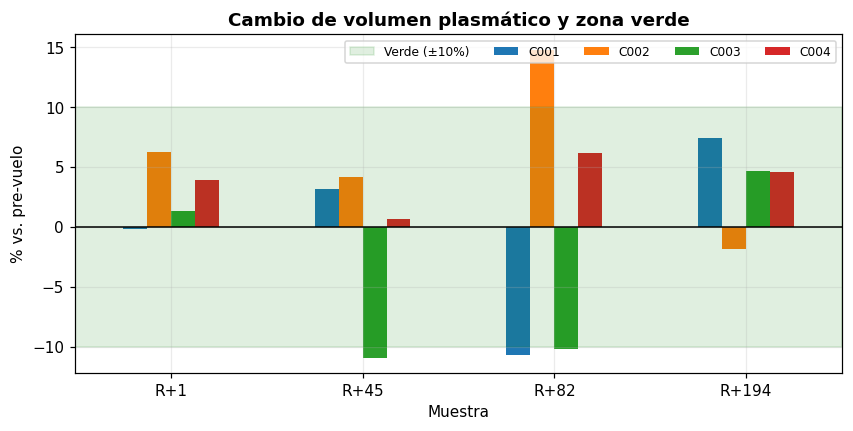

In [62]:
dvp = metricas['Cambio_VP_pct']
metricas['VP_sem'] = pd.Series(np.select([dvp.abs() >= UMBRAL_VP[1], dvp.abs() >= UMBRAL_VP[0]], [2, 1], default=0),
                               index=metricas.index).where(dvp.notna())

vp = (metricas[post_vuelo].pivot(index='Muestra', columns='Tripulante', values='Cambio_VP_pct')
      .loc[['R+1', 'R+45', 'R+82', 'R+194']])
ax = vp.plot.bar(figsize=(9, 4)); ax.axhline(0, color='k', lw=1)
ax.axhspan(-UMBRAL_VP[0], UMBRAL_VP[0], color='green', alpha=.12, label=f'Verde (±{UMBRAL_VP[0]}%)')
ax.set_ylabel('% vs. pre-vuelo'); ax.legend(ncol=5, fontsize=8)
ax.set_title('Cambio de volumen plasmático y zona verde', fontweight='bold')
plt.xticks(rotation=0); plt.show()

### 5.4 Semáforo por sistema del cuerpo
Agrupa los indicadores en zonas que luego serán clicables en la figura humana. Se toma el peor semáforo de cada grupo.

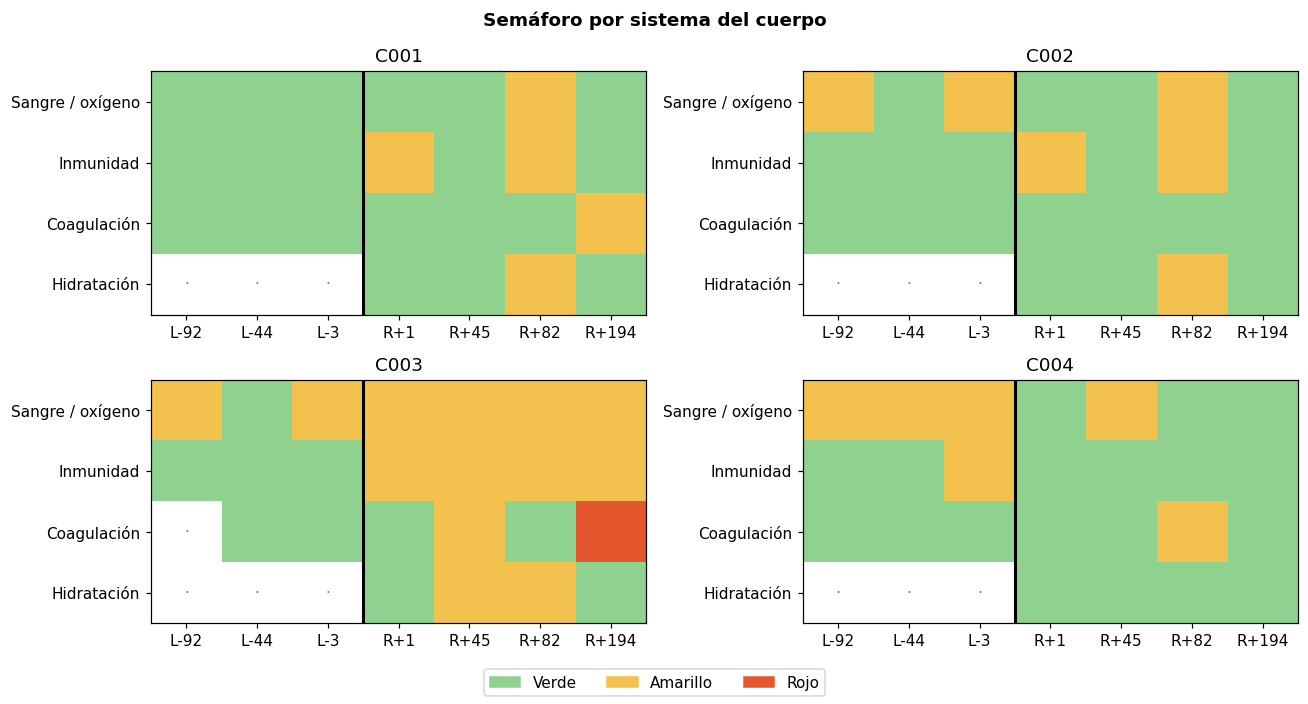

,Sistema,Indicadores,Peligro asociado (a verificar)
0,Sangre / oxígeno,"Hb, Hct, RBC","Microgravedad y radiación: destrucción de glóbulos rojos (""anemia espacial"")"
1,Inmunidad,"WBC, neutrófilos, linfocitos, NLR","Radiación, estrés por aislamiento y entorno cerrado"
2,Coagulación,Plaquetas,Radiación (médula ósea)
3,Hidratación,Volumen plasmático,Desplazamiento de líquidos en microgravedad


In [63]:
SIS = {'SIS_sangre': 'Sangre / oxígeno', 'SIS_inmune': 'Inmunidad',
       'SIS_coag': 'Coagulación', 'SIS_hidrat': 'Hidratación'}
GRUPOS = {'SIS_sangre': ['Hb_sem', 'Hct_sem', 'RBC_sem'],
          'SIS_inmune': ['WBC_sem', 'Neut_sem', 'Linf_sem', 'NLR_sem'],
          'SIS_coag':   ['Plaq_sem'],
          'SIS_hidrat': ['VP_sem']}
for s, cols in GRUPOS.items():
    metricas[s] = metricas[cols].max(axis=1, skipna=True)

mapa_sem(list(SIS), list(SIS.values()), 'Semáforo por sistema del cuerpo')

# Relación sistema ↔ peligro del vuelo espacial (hipótesis de trabajo; cita la fuente de NASA HRP)
pd.DataFrame({
    'Sistema': list(SIS.values()),
    'Indicadores': ['Hb, Hct, RBC', 'WBC, neutrófilos, linfocitos, NLR', 'Plaquetas', 'Volumen plasmático'],
    'Peligro asociado (a verificar)': [
        'Microgravedad y radiación: destrucción de glóbulos rojos ("anemia espacial")',
        'Radiación, estrés por aislamiento y entorno cerrado',
        'Radiación (médula ósea)',
        'Desplazamiento de líquidos en microgravedad']})

### 5.5 Semáforo global y conteo de alertas por muestra

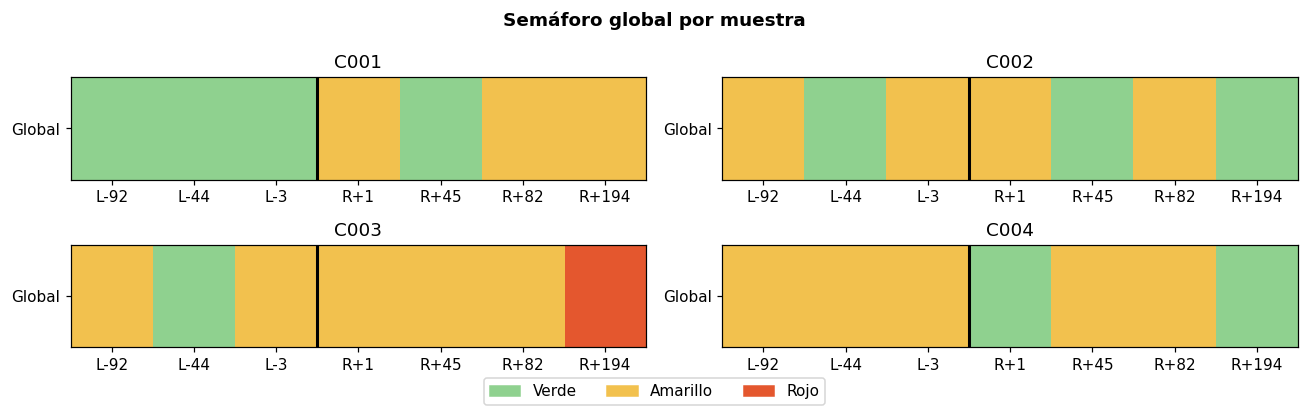

,Tripulante,Muestra,SEM_global_txt,N_amarillo,N_rojo,Motivo
0,C001,L-92,Verde,0,0,—
1,C001,L-44,Verde,0,0,—
2,C001,L-3,Verde,0,0,—
3,C001,R+1,Amarillo,1,0,Linf
4,C001,R+45,Verde,0,0,—
5,C001,R+82,Amarillo,4,0,"Neut, Hb, RBC, VP"
6,C001,R+194,Amarillo,1,0,Plaq
7,C002,L-92,Amarillo,1,0,RBC
8,C002,L-44,Verde,0,0,—
9,C002,L-3,Amarillo,3,0,"Hb, Hct, RBC"


In [64]:
sem_cols = [f'{ab}_sem' for ab in IND] + ['NLR_sem', 'VP_sem']
metricas['SEM_global'] = metricas[sem_cols].max(axis=1)
metricas['N_amarillo'] = (metricas[sem_cols] == 1).sum(axis=1)
metricas['N_rojo'] = (metricas[sem_cols] == 2).sum(axis=1)
metricas['SEM_global_txt'] = metricas['SEM_global'].map(SEM_TXT)
metricas['Motivo'] = metricas[sem_cols].apply(
    lambda r: ', '.join(c.replace('_sem', '') for c in sem_cols if r[c] >= 1) or '—', axis=1)

mapa_sem(['SEM_global'], ['Global'], 'Semáforo global por muestra')
metricas[['Tripulante', 'Muestra', 'SEM_global_txt', 'N_amarillo', 'N_rojo', 'Motivo']]

### 5.6 Índice de salud (0 a 100), base de la gamificación
100 menos 10 puntos por indicador en amarillo y 25 por cada uno en rojo (propuesta).

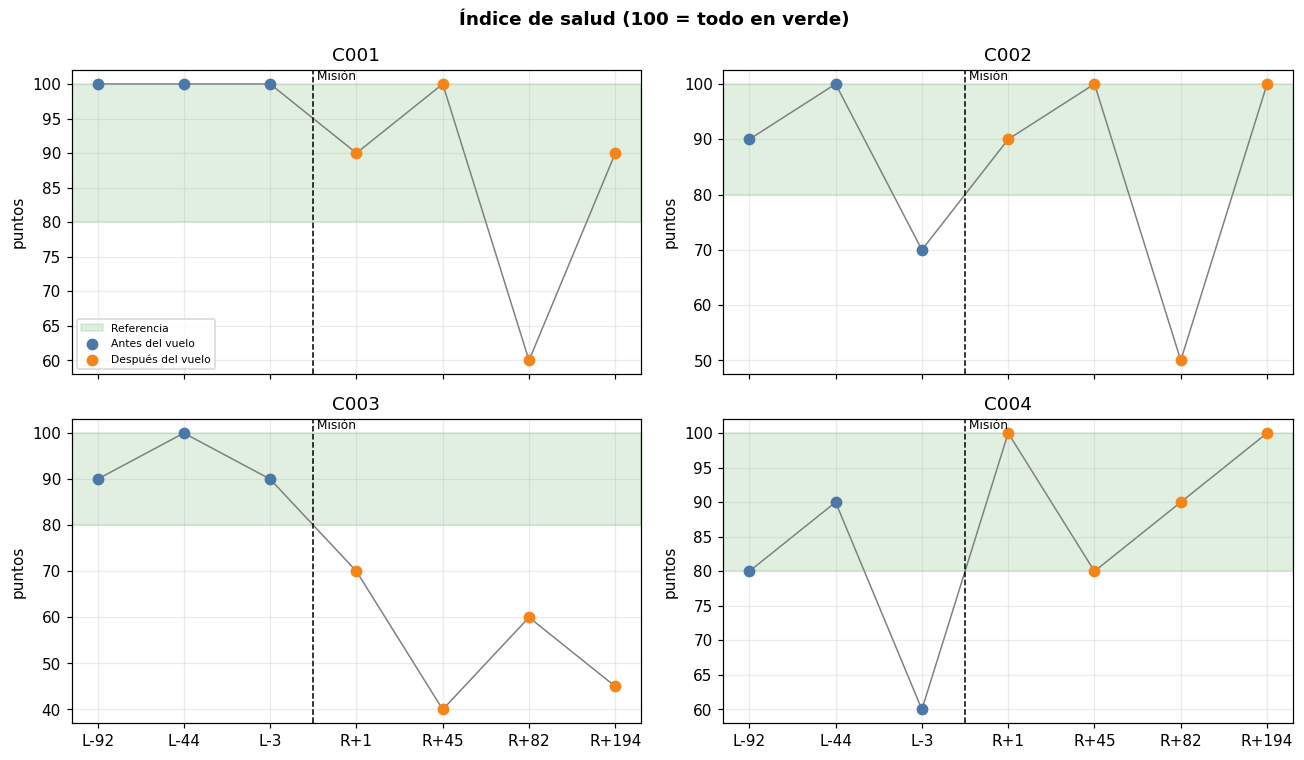

(<Figure size 1320x770 with 4 Axes>,
 array([[<Axes: title={'center': 'C001'}, ylabel='puntos'>,
         <Axes: title={'center': 'C002'}, ylabel='puntos'>],
        [<Axes: title={'center': 'C003'}, ylabel='puntos'>,
         <Axes: title={'center': 'C004'}, ylabel='puntos'>]], dtype=object))

In [65]:
metricas['Indice_salud'] = (100 - 10 * metricas['N_amarillo'] - 25 * metricas['N_rojo']).clip(0, 100)

linea('Indice_salud', 'Índice de salud (100 = todo en verde)', 'puntos', banda=(80, 100))

### 5.7 Índice de desviación vs. línea base
Cada cambio % se divide por su umbral amarillo, así que **1 = umbral amarillo**. Las muestras pre-vuelo muestran la variabilidad natural de cada persona.

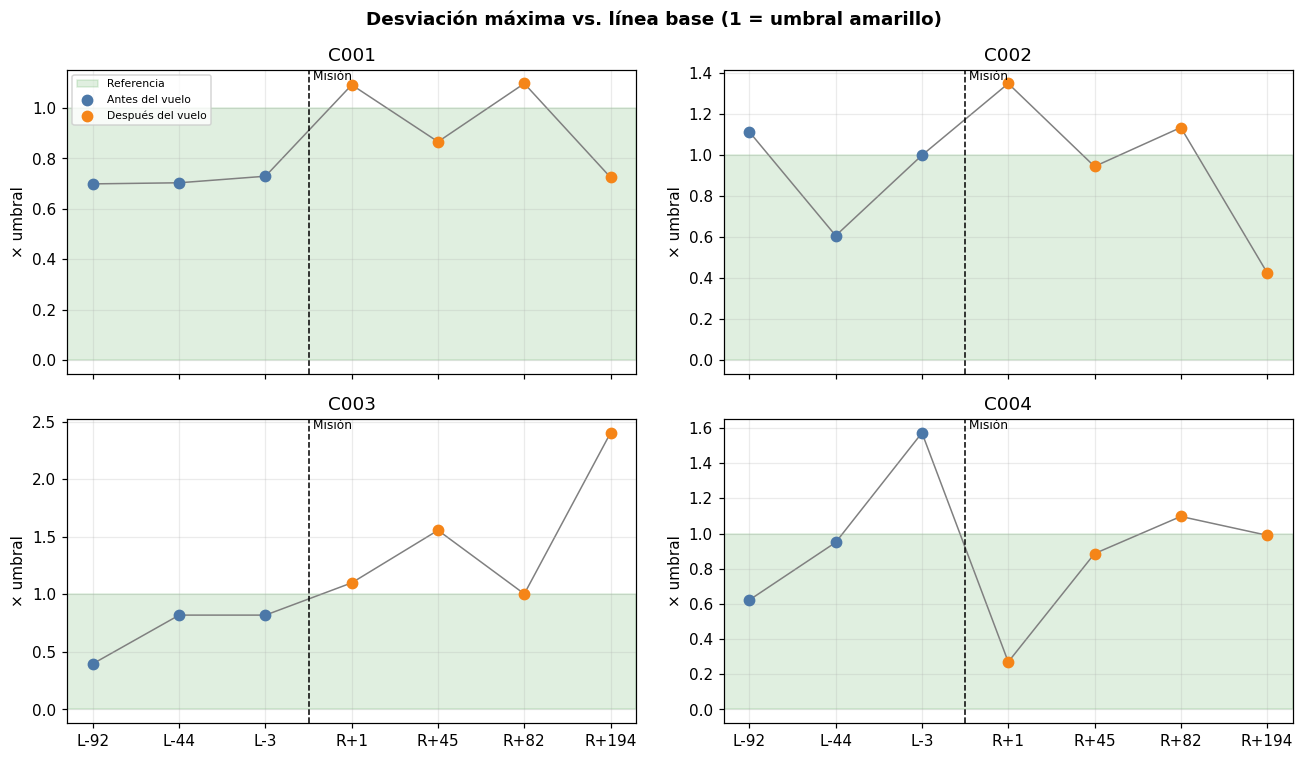

,Tripulante,Muestra,Desv_media,Desv_max,Desv_indicador_max
3,C001,R+1,0.43,1.09,Linf
4,C001,R+45,0.40,0.87,Neut
5,C001,R+82,0.66,1.10,Neut
6,C001,R+194,0.56,0.72,Linf
10,C002,R+1,0.48,1.35,Linf
11,C002,R+45,0.38,0.95,Linf
12,C002,R+82,0.69,1.14,Hct
13,C002,R+194,0.21,0.43,Linf
17,C003,R+1,0.52,1.10,Neut
18,C003,R+45,0.82,1.56,RBC


In [66]:
rel = pd.DataFrame({ab: metricas[f'{ab}_cambio_pct'].abs() / UMBRAL_CAMBIO[ab][0] for ab in IND})
metricas['Desv_media'] = rel.mean(axis=1)
metricas['Desv_max'] = rel.max(axis=1)
metricas['Desv_indicador_max'] = rel.idxmax(axis=1)

linea('Desv_max', 'Desviación máxima vs. línea base (1 = umbral amarillo)', '× umbral', banda=(0, 1))
metricas.loc[post_vuelo, ['Tripulante', 'Muestra', 'Desv_media', 'Desv_max', 'Desv_indicador_max']].round(2)

### 5.8 Días a recuperación
"Recuperado" = primera muestra post-vuelo desde la que `Desv_max ≤ 1` hasta R+194.

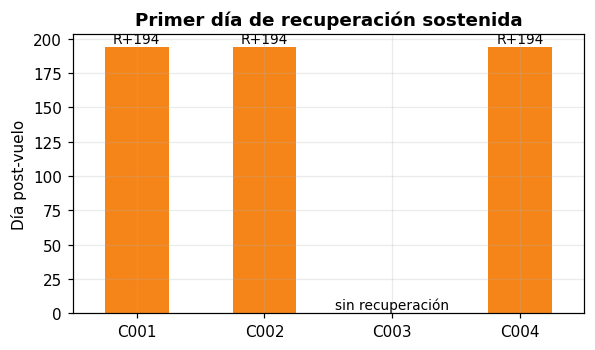

In [67]:
rec = {}
for t, g in metricas[post_vuelo].sort_values('Días').groupby('Tripulante'):
    ok = (g['Desv_max'] <= 1).values
    sostenido = np.logical_and.accumulate(ok[::-1])[::-1]       # ok desde aquí hasta el final
    rec[t] = g['Días'].values[sostenido.argmax()] if sostenido.any() else np.nan
metricas['Dia_recuperacion'] = metricas['Tripulante'].map(rec)

s = pd.Series(rec)
ax = s.fillna(0).plot.bar(color=C_POST, figsize=(6, 3.3))
for i, (t, v) in enumerate(s.items()):
    ax.text(i, (0 if np.isnan(v) else v) + 3, 'sin recuperación' if np.isnan(v) else f'R+{int(v)}',
            ha='center', fontsize=9)
ax.set_ylabel('Día post-vuelo'); ax.set_title('Primer día de recuperación sostenida', fontweight='bold')
plt.xticks(rotation=0); plt.show()

### 5.9 Regla de escalamiento: ¿cuándo avisar al cirujano de vuelo?

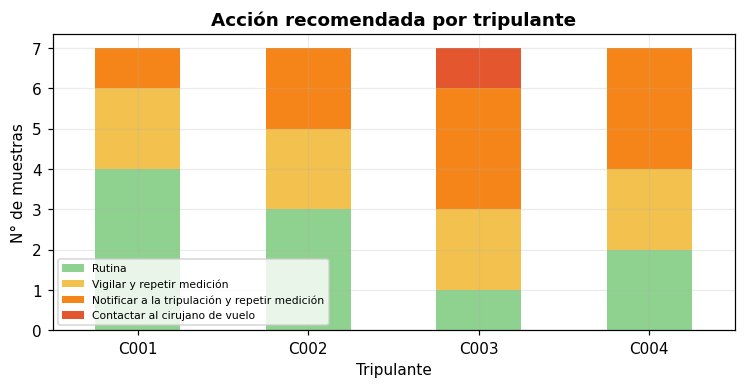

,Tripulante,Fase de Vuelo,Muestra,Accion,Motivo
3,C001,Después del Vuelo,R+1,Vigilar y repetir medición,Linf
5,C001,Después del Vuelo,R+82,Notificar a la tripulación y repetir medición,"Neut, Hb, RBC, VP"
6,C001,Después del Vuelo,R+194,Vigilar y repetir medición,Plaq
7,C002,Antes del Vuelo,L-92,Vigilar y repetir medición,RBC
9,C002,Antes del Vuelo,L-3,Notificar a la tripulación y repetir medición,"Hb, Hct, RBC"
10,C002,Después del Vuelo,R+1,Vigilar y repetir medición,Linf
12,C002,Después del Vuelo,R+82,Notificar a la tripulación y repetir medición,"Linf, Hb, Hct, RBC, VP"
14,C003,Antes del Vuelo,L-92,Vigilar y repetir medición,Hb
16,C003,Antes del Vuelo,L-3,Vigilar y repetir medición,Hb
17,C003,Después del Vuelo,R+1,Notificar a la tripulación y repetir medición,"WBC, Neut, Hb"


In [68]:
rojo = metricas['N_rojo'] >= 1
dos_amarillos = metricas['N_amarillo'] >= 2
un_amarillo = metricas['N_amarillo'] == 1
metricas['Accion'] = np.select(
    [rojo, dos_amarillos, un_amarillo],
    ['Contactar al cirujano de vuelo', 'Notificar a la tripulación y repetir medición', 'Vigilar y repetir medición'],
    default='Rutina')

ORDEN = ['Rutina', 'Vigilar y repetir medición', 'Notificar a la tripulación y repetir medición',
         'Contactar al cirujano de vuelo']
COL_ACC = dict(zip(ORDEN, [SEM_COL[0], SEM_COL[1], '#f58518', SEM_COL[2]]))
ct = metricas.groupby(['Tripulante', 'Accion']).size().unstack(fill_value=0)
ct = ct.reindex(columns=[c for c in ORDEN if c in ct.columns])
ax = ct.plot.bar(stacked=True, color=[COL_ACC[c] for c in ct.columns], figsize=(8, 3.5))
ax.set_ylabel('N° de muestras'); ax.set_title('Acción recomendada por tripulante', fontweight='bold')
ax.legend(fontsize=7); plt.xticks(rotation=0); plt.show()

metricas.loc[metricas['Accion'] != 'Rutina', ['Tripulante', 'Fase de Vuelo', 'Muestra', 'Accion', 'Motivo']]